<div align="center">

# <span style="color:#1976D2;">Customer Churn Prediction and Retention Strategy Using Machine Learning</span>

**Domain:** E-Commerce

**Project Type:** Supervised Machine Learning — Binary Classification

**Target Variable:** Churn

**Unit of Analysis:** Customer Account

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, and XGBoost

</div>

**Execution note:** The EDA and preprocessing cells are assembled from Milestone 1; the model comparison and financial evaluation follow Milestone 2. Saved modelling outputs have been retained where available. Run all cells in order against `data/Customer Churn Data.xlsx` and regenerate the HTML before formal submission; this reorganised version has not yet passed a full fresh execution.

## <span style="color:#1976D2;">Business Understanding & Project Definition</span>

---

### Business Problem Definition


Customer retention is a major challenge in the competitive E-Commerce industry. Losing an account can result in the loss of multiple customers and associated revenue, as each account may have several users.

The company needs a predictive model to identify accounts likely to churn and recommend targeted retention campaigns.

However, retention incentives must be financially sustainable. The challenge is therefore to predict churn accurately while recommending cost-effective strategies that protect revenue and profitability.


---

### Project Objectives



**Primary Objective:** Develop a machine learning model to predict account churn and recommend financially viable retention strategies.

| Objective | Expected Outcome |
|---|---|
| Explore customer data | Understand churn patterns and account characteristics |
| Identify churn drivers | Determine factors associated with account churn |
| Develop predictive models | Predict the probability of account churn |
| Evaluate model performance | Select the most effective classification model |
| Segment at-risk accounts | Identify accounts requiring retention intervention |
| Recommend retention campaigns | Propose targeted, cost-effective offers |



---
### Dataset Overview

The dataset contains account-level information covering customer characteristics, service interactions, satisfaction, and revenue.

| Category | Variables |
|---|---|
| Identifier | AccountID |
| Target | Churn |
| Account Profile | Tenure, City_Tier, Account_user_count, account_segment |
| Demographics | Gender, Marital_Status |
| Customer Service | CC_Contacted_L12m, Service_Score, CC_Agent_Score, Complain_l12m, Day_Since_CC_connect |
| Revenue & Incentives | rev_per_month, rev_growth_yoy, coupon_used_l12m, cashback_l12m |
| Customer Preferences | Payment, Login_device |

**Target Variable:** Churn (binary classification)

**Unit of Analysis:** Account

AccountID will be excluded from model training because it is a unique identifier.




---
### Methodology

The project will follow a structured machine learning workflow.

```text
                         CHURNGUARD — PROJECT WORKFLOW

+--------------------------- DATA & MODEL DEVELOPMENT ---------------------------+
|                                                                                |
|  +---------------+   +---------------+   +---------------+   +---------------+ |
|  | 1. Data       |-->| 2. Exploratory|-->| 3. Data       |-->| 4. Model      | |
|  | Understanding |   | Analysis      |   | Preprocessing |   | Development   | |
|  +---------------+   +---------------+   +---------------+   +---------------+ |
+--------------------------------------------------------------------------|-----+
                                                                           |
                +----------------------------------------------------------+
                |
                v
+----------------------- EVALUATION & STRATEGY --------+        +-------------- STREAMLIT APPLICATION -----------------+
|                                                      |        |                                                      |
| +-------------+  +-------------+  +----------------+ |        | +--------------------------------------------------+ |
| | 5. Model    |->| 6. Churn    |->| 7. Retention   |--------> |          8. ChurnGuard Deployment|                   |
| | Evaluation  |  | Segmentation|  | Strategy & ROI | |        | +--------------------------------------------------+ |
| +-------------+  +-------------+  +----------------+ |        | Single / Batch Prediction  with Email Notification   |
|                                                      |        | Risk Scores & Recommendations                        |
|                                                      |        | CSV Export & Model Info                              |
+------------------------------------------------------+        +------------------------------------------------------+

---
### Success Criteria and Expected Deliverables


| Area | Success Criteria / Deliverable |
|---|---|
| Data Quality | Clean and validated dataset |
| Predictive Performance | Model with strong performance against baseline metrics |
| Churn Insights | Identification of key factors associated with churn |
| Risk Segmentation | Account-level churn probabilities and risk categories |
| Retention Strategy | Targeted campaigns with positive expected financial returns |
| Business Recommendations | Actionable recommendations for reducing account churn |

**Expected Outcome:** A reliable churn prediction model supported by actionable insights and financially sustainable retention recommendations.


## <span style="color:#1976D2;">Libraries, Data Understanding and Exploratory Analysis</span>


---

### Data Understanding

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

#### Environment Setup & Data Loading 

In [1]:
# Install the required libraries

# !python -m pip install --upgrade pip
# !python -m pip install pandas numpy matplotlib seaborn scikit-learn xgboost openpyxl ipykernel jupyter

In [2]:
# Import the necessary libraries for data analysis, visualization, and machine learning.

# Standard library imports
from pathlib import Path
import warnings
import os
import sys
from dotenv import load_dotenv
from getpass import getpass
from datetime import datetime
import time

# Data manipulation and numerical computing
import pandas as pd
import numpy as np
import math

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import sweetviz as sv
from mpl_toolkits.mplot3d import Axes3D
import shap
import json

# Machine learning utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.base import clone
from sklearn.model_selection import ParameterGrid
import joblib


# Classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import json, joblib
from IPython.display import display
from xgboost import XGBClassifier

# Model evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, average_precision_score

# Suppress non-critical warnings for cleaner notebook output.
# Important modelling warnings should still be investigated.
warnings.filterwarnings("ignore", category=FutureWarning)

# Configure Pandas display settings.
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

# Configure visualization defaults.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Set a reproducible random seed for modelling.
RANDOM_STATE = 42

load_dotenv() 

print("All required libraries imported successfully.")


All required libraries imported successfully.


<hr style="border: 0; border-top: 0.5px solid #2b5390;">

#### Project directories and source workbook

In [3]:
# Locate the project root using existing project folders.
PROJECT_ROOT = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "data" / "Customer Churn Data.xlsx").is_file()
    and (p / "outputs").is_dir()
)

# Set the project root as the working directory.
os.chdir(PROJECT_ROOT)
#print("WORKING DIRECTORY:", PROJECT_ROOT)
print("WORKING DIRECTORY:", f"***/{Path.cwd().name}")


WORKING DIRECTORY: ***/CustomerChurnPrediction


In [4]:
# Define project directories.
INPUT_DIR = PROJECT_ROOT / "data_to_predict" # CSV/XLSX files for batch prediction
WORKFLOW_DIR = PROJECT_ROOT / ".github/workflows" # *.yml files for GitHub Actions
SCRIPT_DIR = PROJECT_ROOT / "scripts" # *.py files for data prediction and model deployment
DATA_DIR = PROJECT_ROOT / "data" # *.csv, *.xlsx files for training and testing
OUTPUT_DIR = PROJECT_ROOT / "outputs" # Notebook, HTML, PDF and figure outputs
MODELS_DIR = PROJECT_ROOT / "models" # *.joblib files for trained models
DEPLOYMENT_DIR = PROJECT_ROOT / ".streamlit" # •.toml files for Streamlit deployment

# Create directories if missing.
for path in [INPUT_DIR, WORKFLOW_DIR,SCRIPT_DIR, DATA_DIR, OUTPUT_DIR,MODELS_DIR, DEPLOYMENT_DIR]:
    path.mkdir(parents=True, exist_ok=True)

# Display directory paths.
print("\nPROJECT DIRECTORIES")
for path in [INPUT_DIR, WORKFLOW_DIR,SCRIPT_DIR, DATA_DIR, OUTPUT_DIR,MODELS_DIR, DEPLOYMENT_DIR]:
    print(f"***/{path.relative_to(PROJECT_ROOT.parent)}")


PROJECT DIRECTORIES
***/CustomerChurnPrediction/data_to_predict
***/CustomerChurnPrediction/.github/workflows
***/CustomerChurnPrediction/scripts
***/CustomerChurnPrediction/data
***/CustomerChurnPrediction/outputs
***/CustomerChurnPrediction/models
***/CustomerChurnPrediction/.streamlit


<hr style="border: 0; border-top: 0.5px solid #2b5390;">


In [5]:
# Load data

FILE_PATH = DATA_DIR / "Customer Churn Data.xlsx"

if FILE_PATH.exists():
    print(f"Dataset found: ***/{FILE_PATH.relative_to(PROJECT_ROOT)}")
else:
    raise FileNotFoundError("Dataset not found in data/ directory.")

Dataset found: ***/data/Customer Churn Data.xlsx


In [6]:
# Load dataset into a pandas DataFrame
df = pd.read_excel(FILE_PATH, sheet_name="Data for DSBA")

# Standardize column names & values by stripping whitespace and converting to lowercase.
df.columns = df.columns.str.strip().str.lower()

df.head()

,accountid,churn,tenure,city_tier,cc_contacted_ly,payment,gender,service_score,account_user_count,account_segment,cc_agent_score,marital_status,rev_per_month,complain_ly,rev_growth_yoy,coupon_used_for_payment,day_since_cc_connect,cashback,login_device
0,20000,1,4,3.00,6.00,Debit Card,Female,3.00,3,Super,2.00,Single,9,1.00,11,1,5,159.93,Mobile
1,20001,1,0,1.00,8.00,UPI,Male,3.00,4,Regular Plus,3.00,Single,7,1.00,15,0,0,120.90,Mobile
2,20002,1,0,1.00,30.00,Debit Card,Male,2.00,4,Regular Plus,3.00,Single,6,1.00,14,0,3,NaN,Mobile
3,20003,1,0,3.00,15.00,Debit Card,Male,2.00,4,Super,5.00,Single,8,0.00,23,0,3,134.07,Mobile
4,20004,1,0,1.00,12.00,Credit Card,Male,2.00,3,Regular Plus,5.00,Single,3,0.00,11,1,3,129.60,Mobile


---

### Exploratory Data Analysis (EDA)

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

#### Exploratory Data Analysis (EDA) - Raw Data
Explore the data, assess its quality, and identify patterns linked to customer churn.

In [7]:
# Standardize column names & values by stripping whitespace and converting to lowercase.
df.columns = df.columns.str.strip().str.lower()

# Set the target column and identifier column for the dataset.

TARGET_COL = "churn"
id_cols = "accountid"

# Display dataset dimensions.
print(f"Dataset Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

# Preview the first five records.
display(df.head())

# Examine column names, data types, and non-null counts.
df.info()

Dataset Shape: 11,260 rows × 19 columns


,accountid,churn,tenure,city_tier,cc_contacted_ly,payment,gender,service_score,account_user_count,account_segment,cc_agent_score,marital_status,rev_per_month,complain_ly,rev_growth_yoy,coupon_used_for_payment,day_since_cc_connect,cashback,login_device
0,20000,1,4,3.00,6.00,Debit Card,Female,3.00,3,Super,2.00,Single,9,1.00,11,1,5,159.93,Mobile
1,20001,1,0,1.00,8.00,UPI,Male,3.00,4,Regular Plus,3.00,Single,7,1.00,15,0,0,120.90,Mobile
2,20002,1,0,1.00,30.00,Debit Card,Male,2.00,4,Regular Plus,3.00,Single,6,1.00,14,0,3,NaN,Mobile
3,20003,1,0,3.00,15.00,Debit Card,Male,2.00,4,Super,5.00,Single,8,0.00,23,0,3,134.07,Mobile
4,20004,1,0,1.00,12.00,Credit Card,Male,2.00,3,Regular Plus,5.00,Single,3,0.00,11,1,3,129.60,Mobile


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11260 entries, 0 to 11259
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   accountid                11260 non-null  int64  
 1   churn                    11260 non-null  int64  
 2   tenure                   11158 non-null  object 
 3   city_tier                11148 non-null  float64
 4   cc_contacted_ly          11158 non-null  float64
 5   payment                  11151 non-null  object 
 6   gender                   11152 non-null  object 
 7   service_score            11162 non-null  float64
 8   account_user_count       11148 non-null  object 
 9   account_segment          11163 non-null  object 
 10  cc_agent_score           11144 non-null  float64
 11  marital_status           11048 non-null  object 
 12  rev_per_month            11158 non-null  object 
 13  complain_ly              10903 non-null  float64
 14  rev_growth_yoy        

**Observation**: The dataset contains 11,260 records and 19 variables. Several columns have missing values, while some numerical features are stored as objects, indicating potential data quality issues requiring cleaning before modelling.

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

#### Data Quality Assessment


##### Check Invalid Values in Numeric Columns

In [8]:
# Identify columns expected to contain numerical values.
numeric_cols = [
    "tenure", "account_user_count", "rev_per_month", "rev_growth_yoy", "coupon_used_for_payment",
    "day_since_cc_connect", "cashback"]

# Identify non-numeric values and summarize them in a table.
invalid_summary = []

for col in numeric_cols:
    invalid = pd.to_numeric(df[col], errors="coerce").isna() & df[col].notna()
    invalid_summary.append({
        "Column": col,
        "Invalid Count": invalid.sum(),
        "Invalid Values": df.loc[invalid, col].astype(str).unique().tolist()[:10]
    })

# Display the summary table.
display(pd.DataFrame(invalid_summary))


,Column,Invalid Count,Invalid Values
0,tenure,116,[#]
1,account_user_count,332,[@]
2,rev_per_month,689,[+]
3,rev_growth_yoy,3,[$]
4,coupon_used_for_payment,3,"[#, $, *]"
5,day_since_cc_connect,1,[$]
6,cashback,2,[$]


##### Correct Invalid Numeric Values

In [9]:
# Create a working copy to preserve the original dataset.
df_clean = df.copy()

# Convert numerical columns; invalid values become NaN.
df_clean[numeric_cols] = df_clean[numeric_cols].apply(pd.to_numeric, errors="coerce")

# Summarize data types and missing values in a table.
summary = pd.DataFrame({
    "Data Type": df_clean[numeric_cols].dtypes.astype(str),
    "Missing Count": df_clean[numeric_cols].isna().sum(),
    "Missing (%)": (df_clean[numeric_cols].isna().mean() * 100).round(2)
})

display(summary.reset_index(names="Column"))

,Column,Data Type,Missing Count,Missing (%)
0,tenure,float64,218,1.94
1,account_user_count,float64,444,3.94
2,rev_per_month,float64,791,7.02
3,rev_growth_yoy,float64,3,0.03
4,coupon_used_for_payment,float64,3,0.03
5,day_since_cc_connect,float64,358,3.18
6,cashback,float64,473,4.20


**Observation**: All seven columns have been successfully converted to `float64`. Missing values range from 0.03% to 7.02%, with `rev_per_month` having the highest (791 records), followed by `cashback` (473) and `Account_user_count` (444).

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

#### Univariate Analysis — Distribution and Outlier Assessment

In [10]:
# EDA: Identify numeric and categorical columns


# Standardize numerical values by stripping whitespace and converting to lowercase.
df_clean = df_clean.apply(lambda col: col.str.strip().str.lower() if col.dtype == "object" else col)

df_eda = df_clean.copy()

features = [c for c in df_eda.columns if c not in [id_cols, TARGET_COL]]

X_eda = df_eda[features].copy()
num_var = X_eda.select_dtypes(include=[np.number]).columns.tolist()
cat_var = [c for c in X_eda.columns if c not in num_var]

print("ID cols:", id_cols)
print("Numeric cols:", num_var)
print("Categorical cols:", cat_var)

ID cols: accountid
Numeric cols: ['tenure', 'city_tier', 'cc_contacted_ly', 'service_score', 'account_user_count', 'cc_agent_score', 'rev_per_month', 'complain_ly', 'rev_growth_yoy', 'coupon_used_for_payment', 'day_since_cc_connect', 'cashback']
Categorical cols: ['payment', 'gender', 'account_segment', 'marital_status', 'login_device']


##### Target Distribution (Univariate)

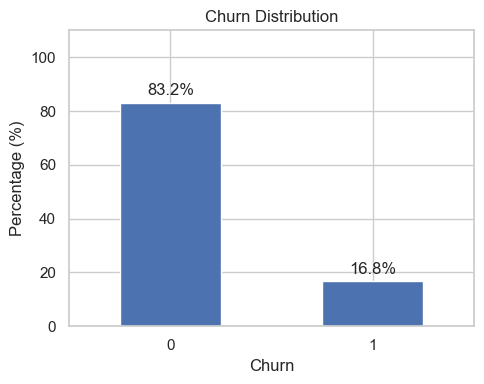

In [11]:
# Plot target class distribution (%).
cs_pct = df_eda[TARGET_COL].value_counts(normalize=True).sort_index() * 100

ax = cs_pct.plot.bar(figsize=(5, 4), rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

ax.set(title=f"{TARGET_COL.title()} Distribution",
       xlabel=TARGET_COL.replace("_", " ").title(),
       ylabel="Percentage (%)",
       ylim=(0, 110))

plt.tight_layout()
plt.show()

The dataset is imbalanced, with 83.2% non-churned customers and 16.8% churned customers, requiring stratified sampling and appropriate evaluation metrics.

##### Numeric Distribution (Univariate)

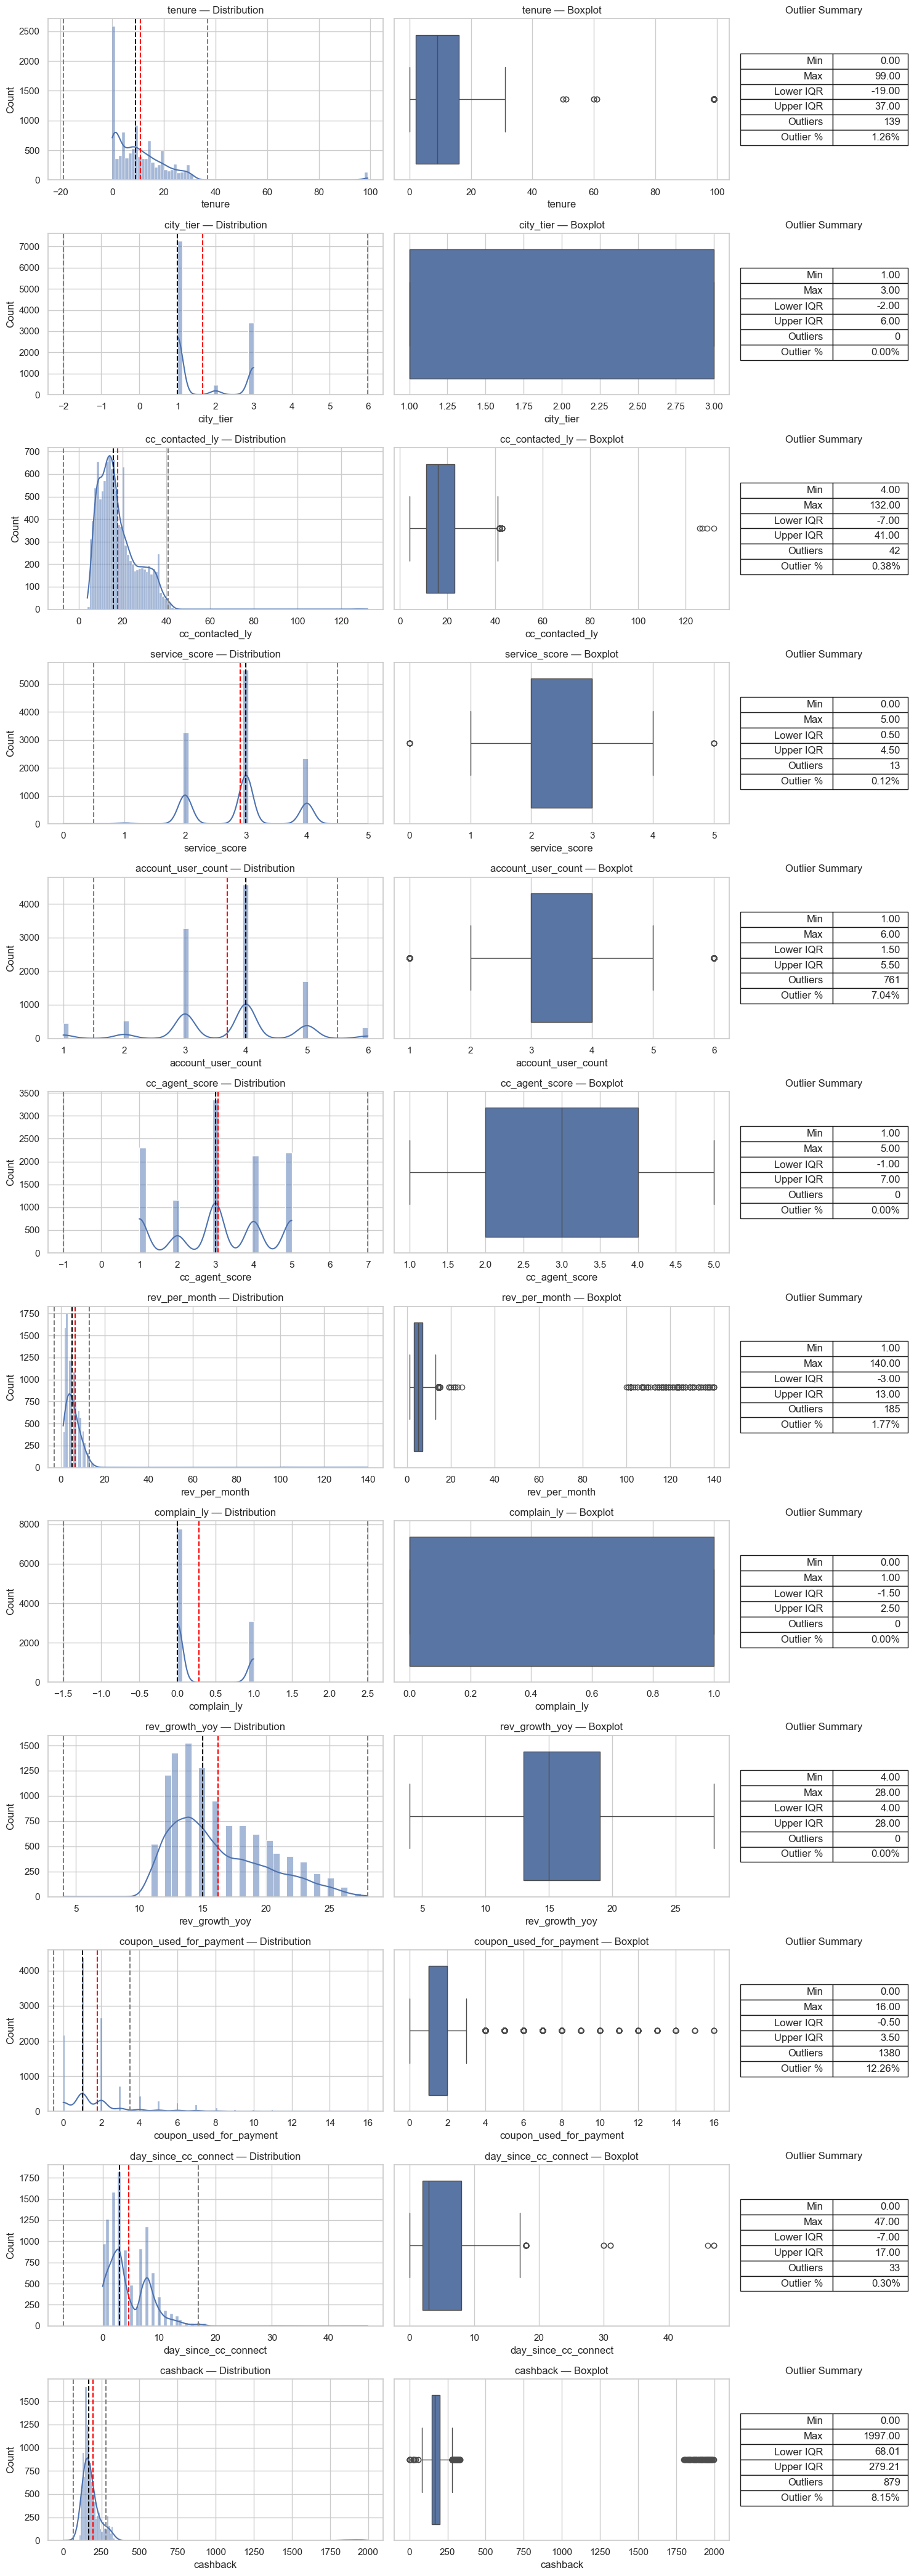

In [12]:
# Numeric Distribution — All Variables
fig, ax = plt.subplots(len(num_var), 3, figsize=(15, 3.5*len(num_var)),
                       gridspec_kw={"width_ratios": [2, 2, 1]}, squeeze=False)

for i, c in enumerate(num_var):
    s = df_eda[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    lf, uf = q1 - 1.5*(q3-q1), q3 + 1.5*(q3-q1)
    outliers = ((s < lf) | (s > uf)).sum()

    # Histogram
    sns.histplot(s, kde=True, ax=ax[i, 0])
    for v, color in [(s.mean(), "red"), (s.median(), "black"), (lf, "gray"), (uf, "gray")]:
        ax[i, 0].axvline(v, color=color, ls="--")
    ax[i, 0].set_title(f"{c} — Distribution")

    # Boxplot
    sns.boxplot(x=s, ax=ax[i, 1])
    ax[i, 1].set_title(f"{c} — Boxplot")

    # Outlier summary
    summary = [["Min", f"{s.min():.2f}"], ["Max", f"{s.max():.2f}"],
               ["Lower IQR", f"{lf:.2f}"], ["Upper IQR", f"{uf:.2f}"],
               ["Outliers", outliers], ["Outlier %", f"{outliers/len(s)*100:.2f}%"]]
    ax[i, 2].axis("off")
    ax[i, 2].table(cellText=summary, loc="center", colWidths=[0.55, 0.45]).scale(1, 1.3)
    ax[i, 2].set_title("Outlier Summary")

plt.tight_layout()
plt.show()


**Outlier Assessment and Treatment**

| Variable                  | Issue Type                                 | Severity | Action Taken                                         |
| ------------------------- | ------------------------------------------ | -------- | ---------------------------------------------------- |
| `tenure`                  | Right skew + extreme values (1.26%)        | Medium   | Retain; validate extremes                            |
| `cc_contacted_ly`         | Right skew (0.38%)                         | Low      | Retain                                               |
| `account_user_count`      | Discrete values flagged by IQR (7.04%)     | Low      | Retain                                               |
| `rev_per_month`           | Strong right skew (1.77%)                  | Medium   | Retain; consider log transform                       |
| `coupon_used_for_payment` | Right skew + outliers (12.26%)             | High     | Retain; consider log transform                       |
| `day_since_cc_connect`    | Right skew (0.30%)                         | Low      | Retain                                               |
| `cashback`                | Strong right skew + extreme values (8.15%) | High     | Retain; validate extremes and consider log transform |

Outliers will be retained because they may reflect genuine customer behaviour and are generally well handled by tree-based models. Skewed variables may be transformed where necessary rather than removing observations.

Note: Transformations are proposed, not yet applied.

##### Categorical Distribution (Univariate)

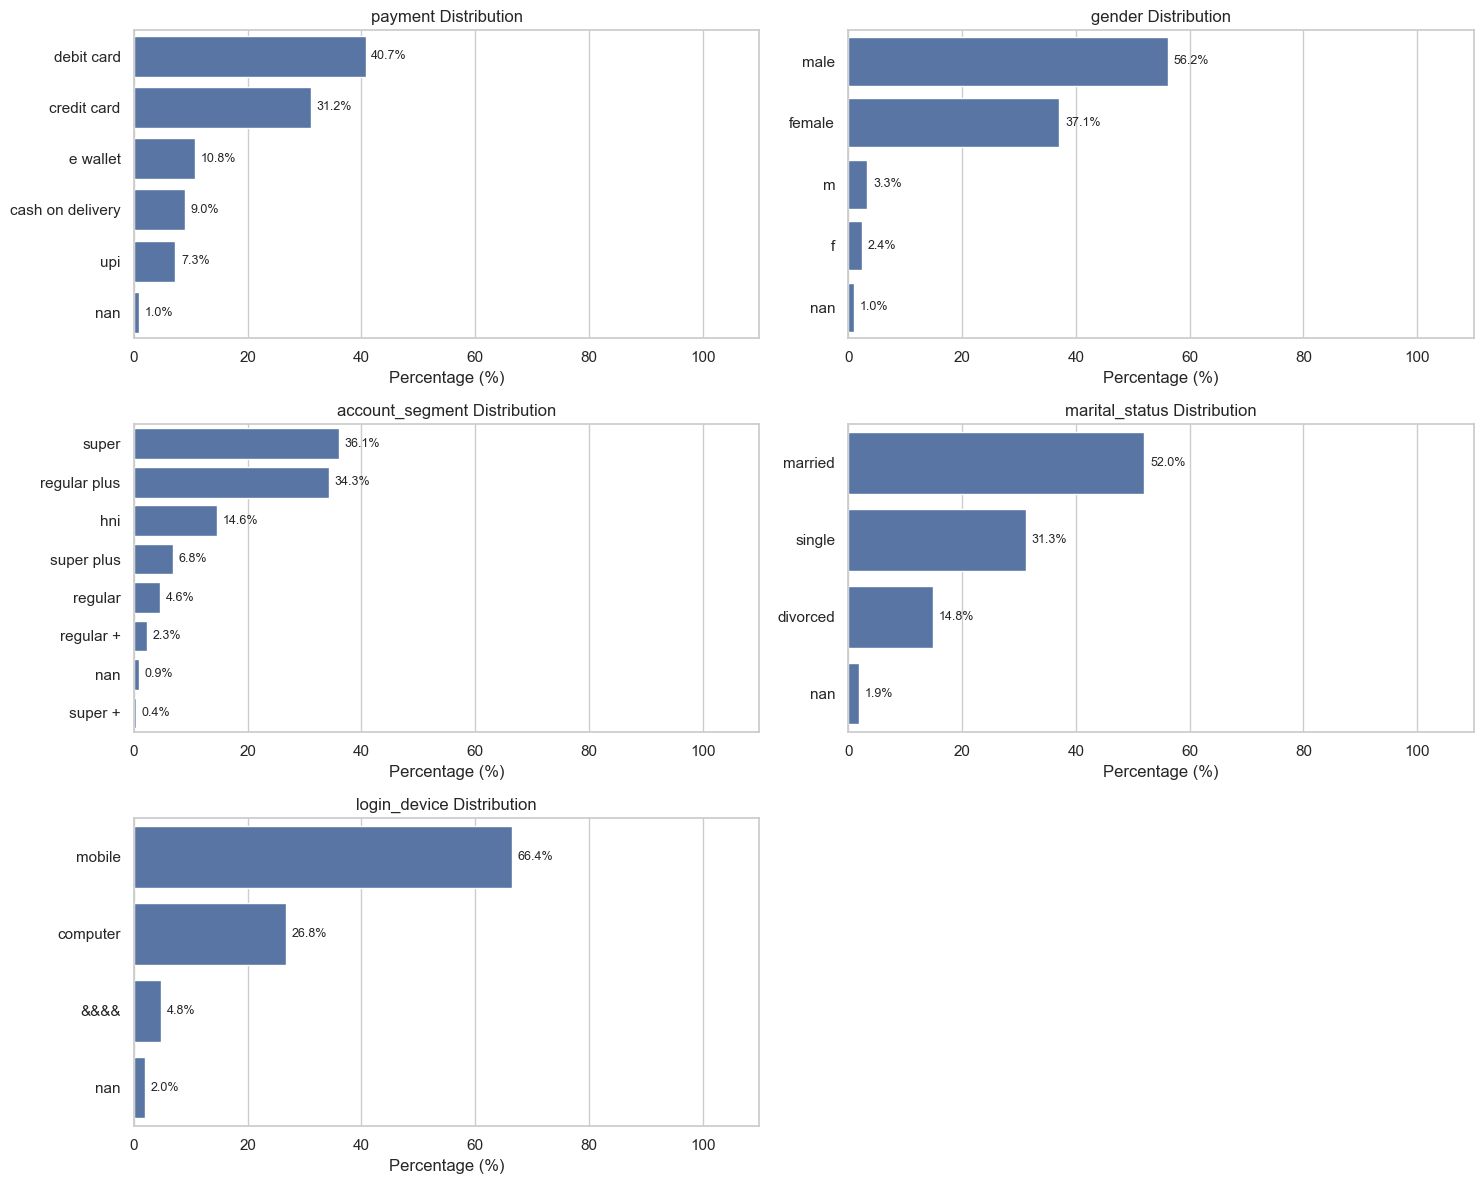

In [13]:
# Categorical Distribution (Univariate)

ncols = 2
nrows = math.ceil(len(cat_var) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4*nrows))
axes = np.array(axes).reshape(-1)

for ax, c in zip(axes, cat_var):
    pct = df_eda[c].value_counts(normalize=True, dropna=False) * 100

    sns.barplot(x=pct.values, y=pct.index.astype(str), ax=ax)
    ax.set(title=f"{c} Distribution", xlabel="Percentage (%)", ylabel="", xlim=(0, 110))

    for i, v in enumerate(pct):
        ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=9)

# Remove unused subplots.
for ax in axes[len(cat_var):]:
    ax.remove()

plt.tight_layout()
plt.show()


**Summary of Categorical Variables — Univariate Analysis**

| Variable          | Key Observation                                                      | Business Insight                                                        |
| ----------------- | -------------------------------------------------------------------- | ----------------------------------------------------------------------- |
| `payment`         | Debit cards (40.7%) and credit cards (31.2%) dominate; 1.0% missing. | Card payments dominate; missing values require imputation.              |
| `gender`          | Male (56.2%), female (37.1%); 1.0% missing and inconsistent labels.  | Standardize labels and impute missing values.                           |
| `account_segment` | Super (36.1%) and Regular Plus (34.3%) dominate; 0.9% missing.       | Higher-tier segments dominate; inconsistent labels require correction.  |
| `marital_status`  | Married customers (52.0%) dominate; 1.9% missing.                    | Married customers form the largest group; imputation required.          |
| `login_device`    | Mobile (66.4%) dominates; 2.0% missing and invalid labels.           | Mobile is the primary access channel; clean invalid and missing values. |

Overall, categorical variables show low missingness (0.9%–2.0%), with mobile usage, card payments, and higher-tier account segments dominating. Missing values will be imputed using the mode on training data, while inconsistent labels will be standardized before modelling.

##### Overall Univariate Summary

- Customer churn is imbalanced, with 83.2% retained and 16.8% churned customers.
- Tenure, revenue, cashback, and coupon usage exhibit right-skewed distributions and outliers.
- Debit and credit cards dominate payment methods, accounting for 71.9% of customers.
- Super and Regular Plus are the largest account segments, representing 70.4% of customers.
- Mobile devices dominate customer access (66.4%).
- Missing values and inconsistent categorical labels require preprocessing before modelling.

**Strategic Implication**

The customer base is predominantly mobile-oriented, card-paying, and concentrated in higher-tier account segments. The imbalanced churn distribution requires stratified sampling and appropriate evaluation metrics, while skewed numerical variables and data quality issues should be addressed during preprocessing to support reliable churn prediction.

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

#### Bivariate Analysis — Categorical Variables vs Target

##### Categorical Distribution (Bivariate)

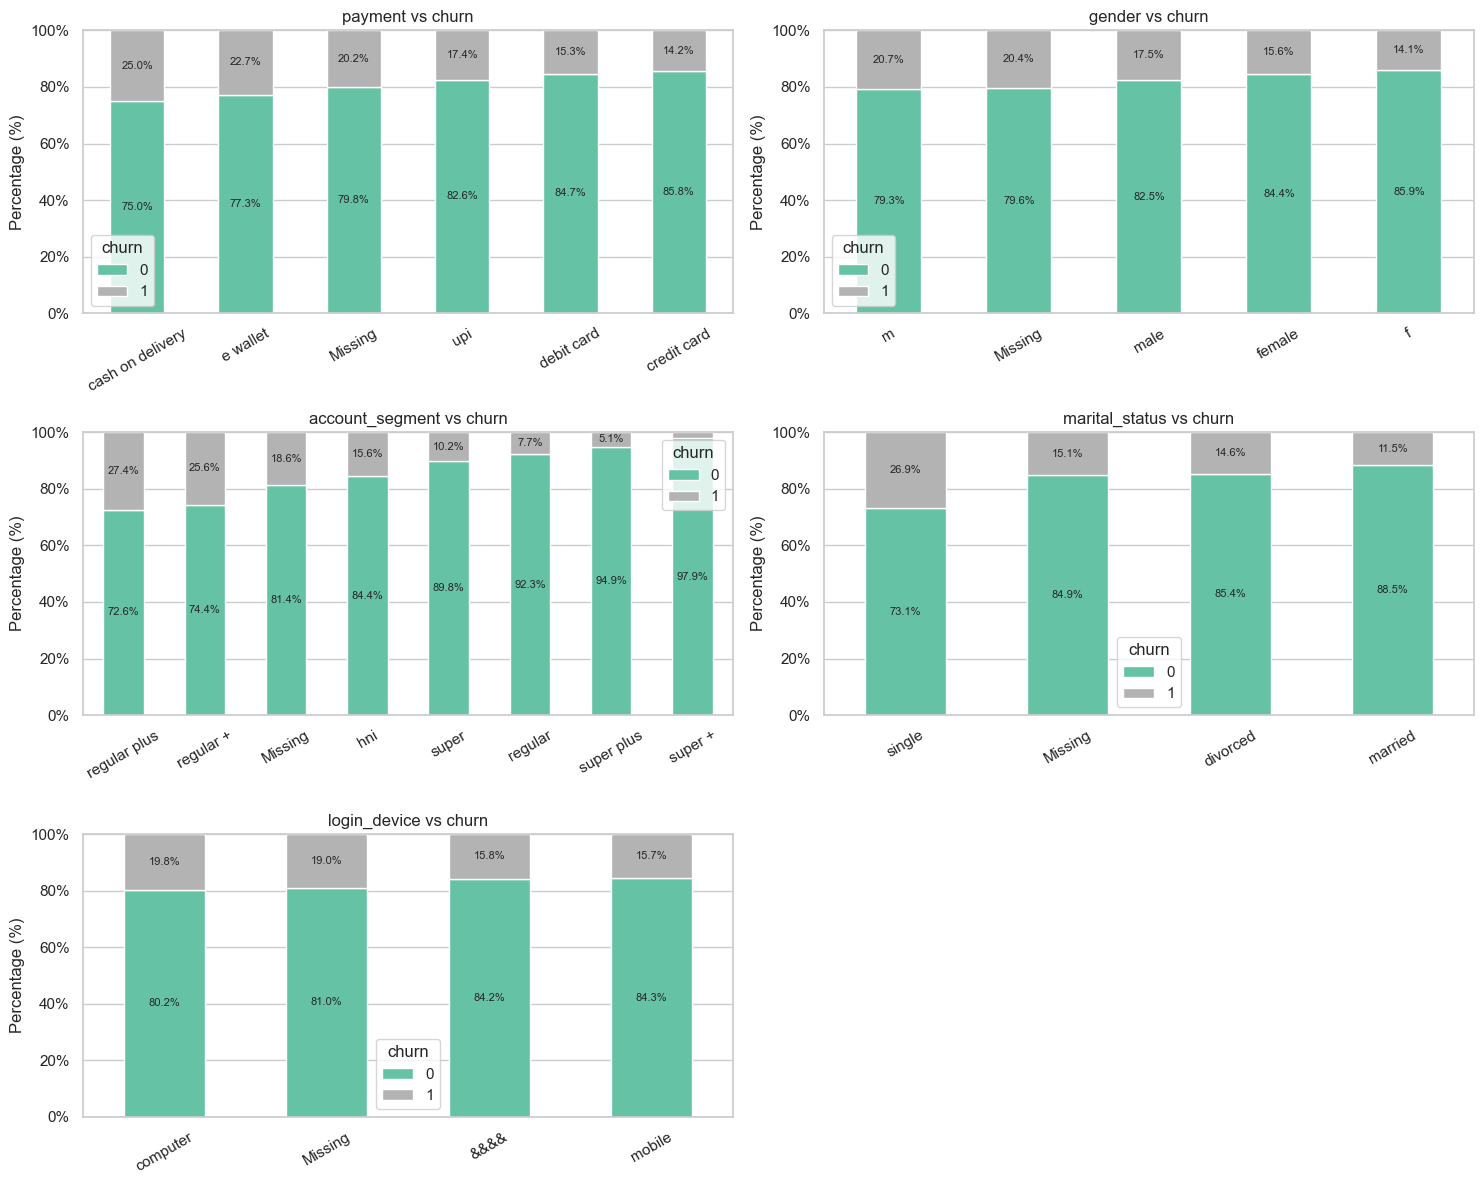

In [14]:
# Bivariate Analysis — Categorical Variables vs Target
ncols = 2
nrows = (len(cat_var) + 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4*nrows))
axes = np.array(axes).reshape(-1)

for ax, c in zip(axes, cat_var):
    # Include missing values as a separate category.
    prop = pd.crosstab(df_eda[c].fillna("Missing"), df_eda[TARGET_COL], normalize="index")
    prop = prop.sort_values(by=1, ascending=False)

    prop.plot.bar(stacked=True, ax=ax, colormap="Set2", rot=0)
    ax.set(title=f"{c} vs {TARGET_COL}", xlabel="", ylabel="Percentage (%)", ylim=(0, 1))
    ax.set_yticks(np.arange(0, 1.1, 0.2), labels=[f"{v:.0%}" for v in np.arange(0, 1.1, 0.2)])
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title=TARGET_COL)

    # Annotate percentages within bars.
    for container in ax.containers:
        ax.bar_label(container, fmt=lambda v: f"{v:.1%}" if v >= 0.05 else "",
                     label_type="center", fontsize=8)

# Remove unused subplots.
for ax in axes[len(cat_var):]:
    ax.remove()

plt.tight_layout()
plt.show()


**Categorical Variables vs. Customer Churn**

| Variable | Key Observation | Impact | Interpretation |
|---|---|---|---|
| `payment` | Cash highest (25.0%); credit card lowest (14.2%). | Moderate | Churn varies by payment method. |
| `gender` | Rates range from 14.1% to 20.7%. | Weak–Moderate | Standardize labels before comparing. |
| `account_segment` | Regular Plus highest (27.4%); Super Plus lowest (~2.1%). | Strong | Rates differ substantially by segment. |
| `marital_status` | Single highest (26.9%); married lowest (11.5%). | Strong | Single customers show higher churn. |
| `login_device` | Computer users: 19.8%; mobile users: 15.7%. | Weak | Rates differ slightly by device. |

Account segment and marital status show the largest differences. Missing and inconsistent categories need cleanup. These are associations, not proof of causation.

##### Numerical Distribution (Bivariate)

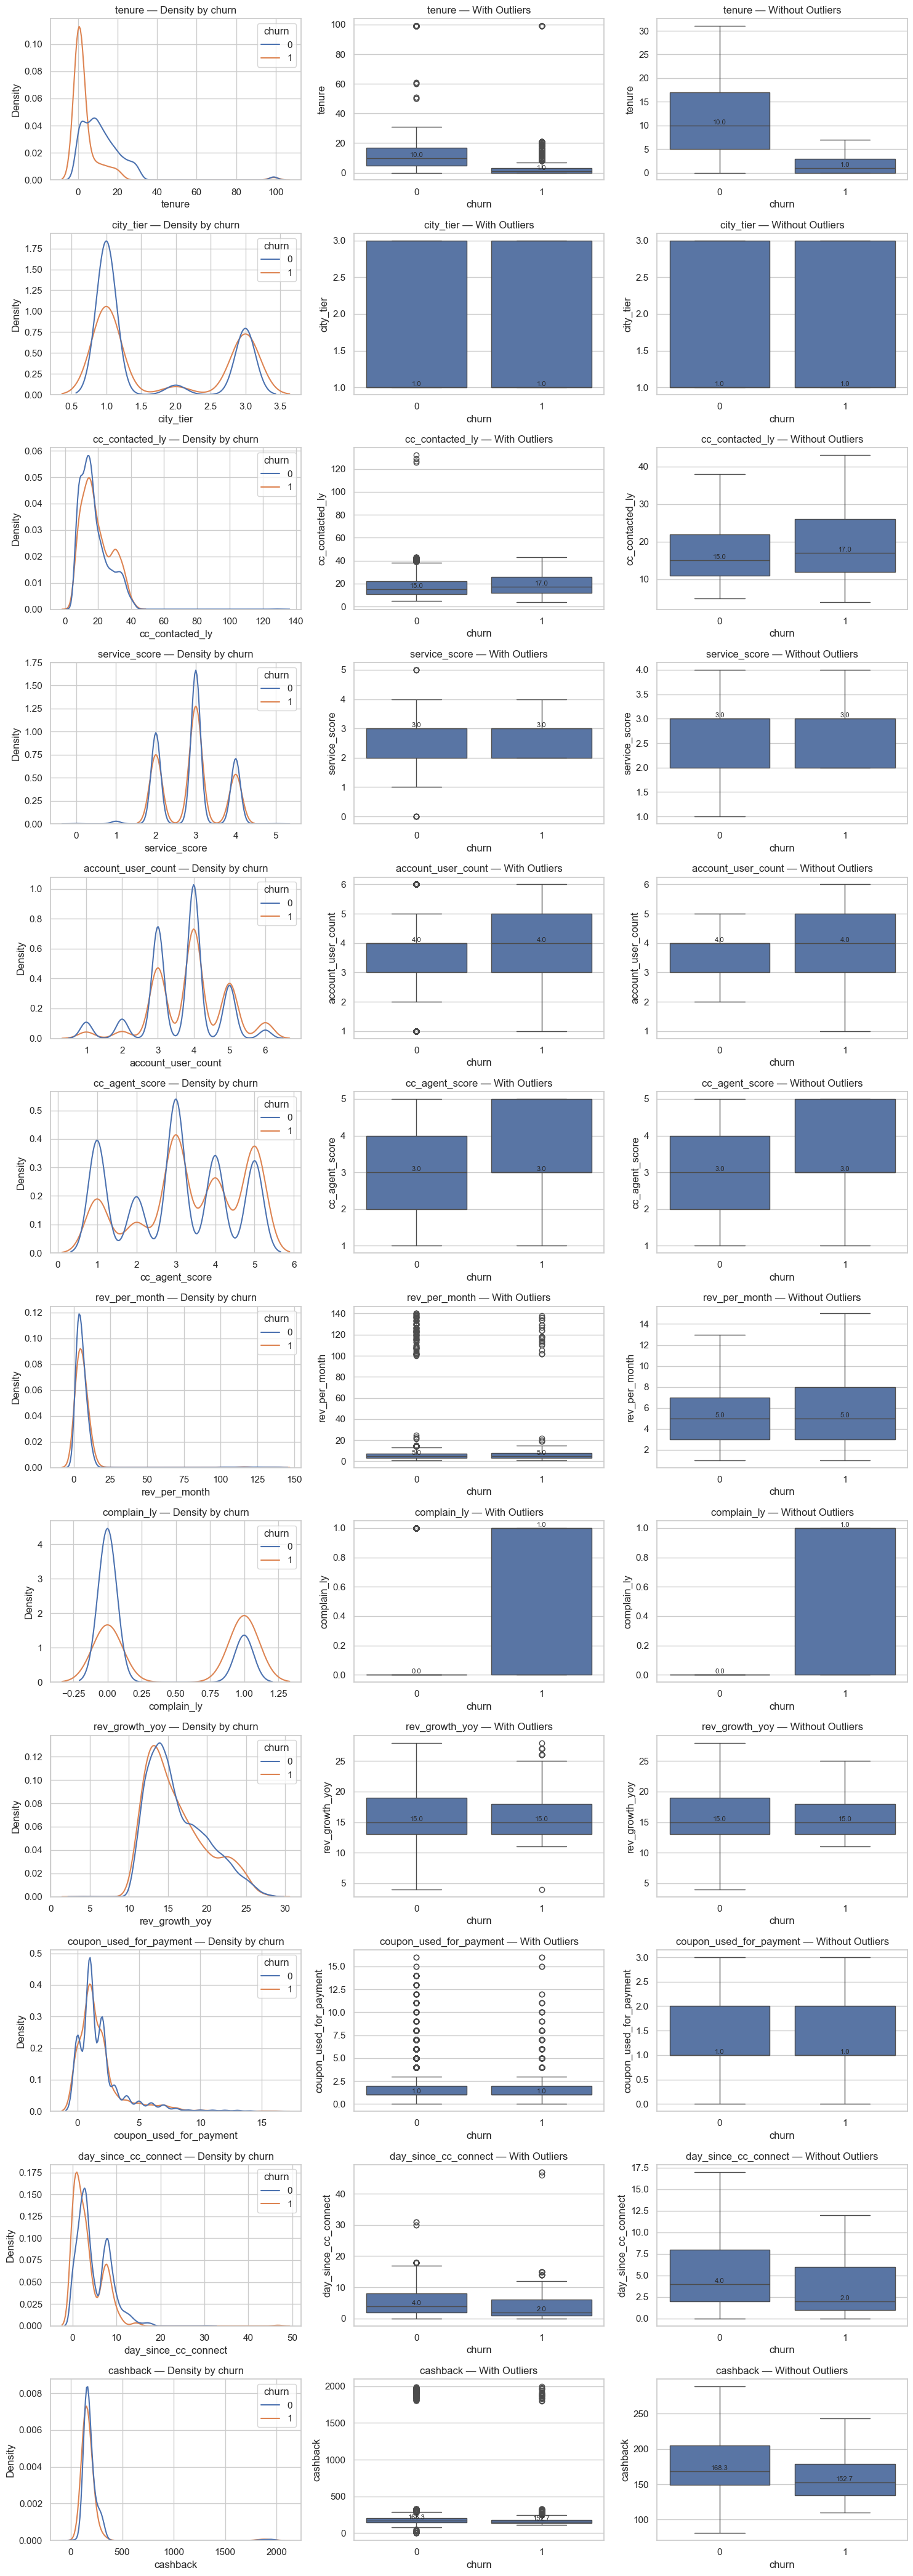

In [15]:
# Numeric Bivariate Analysis — All Variables vs Target
fig, axes = plt.subplots(len(num_var), 3, figsize=(15, 3.5*len(num_var)), squeeze=False)

for i, c in enumerate(num_var):
    # Density by churn status.
    sns.kdeplot(data=df_eda, x=c, hue=TARGET_COL, ax=axes[i, 0], common_norm=False)
    axes[i, 0].set_title(f"{c} — Density by {TARGET_COL}")

    # Boxplots with and without outliers.
    med = df_eda.groupby(TARGET_COL)[c].median()
    for j, show in enumerate([True, False], start=1):
        ax = axes[i, j]
        sns.boxplot(data=df_eda, x=TARGET_COL, y=c, showfliers=show, ax=ax)
        ax.set_title(f"{c} — {'With' if show else 'Without'} Outliers")

        # Annotate median values.
        for k, v in enumerate(med):
            ax.text(k, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()


**Numeric Variables vs. Customer Churn**

| Variable | Retained Median | Churned Median | Pattern | Impact | Interpretation |
|---|---:|---:|---|---|---|
| `tenure` | 10 | 1 | Strong separation | Strong | New customers churn more. |
| `city_tier` | 1 | 1 | Nearly identical | Weak | Little difference. |
| `cc_contacted_ly` | 16 | 17 | Overlap | Weak | Contacts may reflect dissatisfaction. |
| `service_score` | 3 | 3 | Similar | Weak | Little difference. |
| `account_user_count` | 3 | 4 | Noticeable shift | Moderate | Larger accounts churn more. |
| `cc_agent_score` | 3 | 4 | Noticeable shift | Moderate | Scores differ by churn status. |
| `rev_per_month` | 5 | 5 | Overlap; right-skewed | Weak | Revenue poorly separates churn. |
| `complain_ly` | 0 | 1 | Strong separation | Strong | Complaints relate to higher churn. |
| `rev_growth_yoy` | 15 | 15 | Nearly identical | Weak | Little difference. |
| `coupon_used_for_payment` | 1 | 1 | Overlap; right-skewed | Weak | Little separation. |
| `day_since_cc_connect` | 4 | 2 | Noticeable shift | Moderate | Recent contact relates to churn. |
| `cashback` | ~168 | ~152 | Overlap; right-skewed | Moderate | Lower cashback relates to churn. |

Tenure and complaints show the clearest differences; impact levels are descriptive, not tests of significance.

##### Overall Bivariate Summary

- Tenure and complaint history show the strongest associations with customer churn.
- Account segment and marital status reveal significant differences in observed churn rates.
- Payment method influences churn patterns, with cash-on-delivery customers showing higher churn.
- Account user count, agent score, contact recency, and cashback show moderate associations with churn.
- Gender and login device show relatively weak differences.
- Revenue, service score, city tier, and coupon usage provide limited standalone separation.

**Strategic Implication**

Customer churn is primarily associated with customer tenure, complaint history, account segmentation, and engagement patterns. Retention strategies should prioritize new customers, customers with complaints, and high-churn account segments, while multivariate modelling will help validate the most important predictors.

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

#### Multivariate Analysis (Feature–Feature Relationships)

- Assesses predictor relationships to uncover redundancy and interaction effects.

##### Numerical Correlation

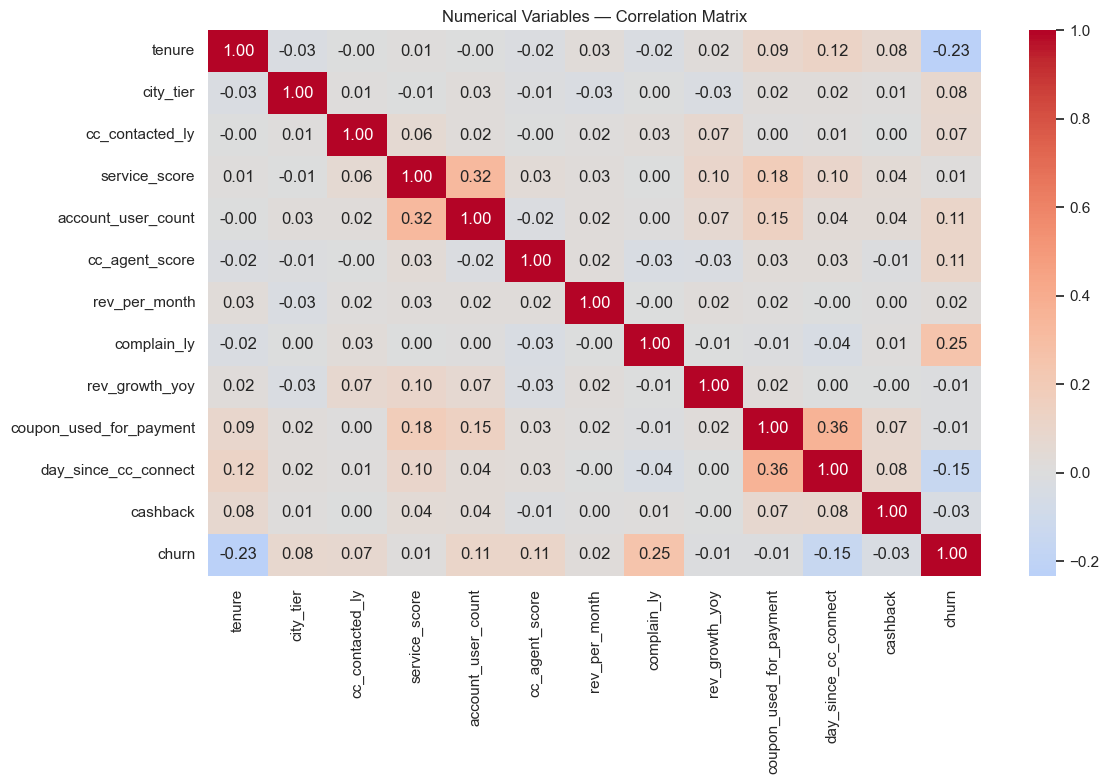

In [16]:
# Multivariate Analysis — Numerical Correlation
corr = df_eda[num_var + [TARGET_COL]].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Numerical Variables — Correlation Matrix")
plt.tight_layout()
plt.show()


**Correlation Analysis**

| Variable | Correlation | Impact | Summary |
|---|---:|---|---|
| `complain_ly` | +0.25 | Moderate | Complaints relate to higher churn. |
| `tenure` | -0.23 | Moderate | Longer tenure relates to lower churn. |
| `day_since_cc_connect` | -0.15 | Weak | Recent contact relates to higher churn. |
| `account_user_count` | +0.11 | Weak | Larger accounts show slightly higher churn. |
| `cc_agent_score` | +0.11 | Weak | Slight positive association. |
| `city_tier` | +0.08 | Weak | Little linear association. |
| Other numeric variables | -0.03 to +0.07 | Negligible | Little linear association. |

Complaints and tenure have the strongest correlations with churn. Predictor correlations are generally low; weak correlations do not exclude nonlinear effects or interactions.

##### Numerical Analysis — Pairplot

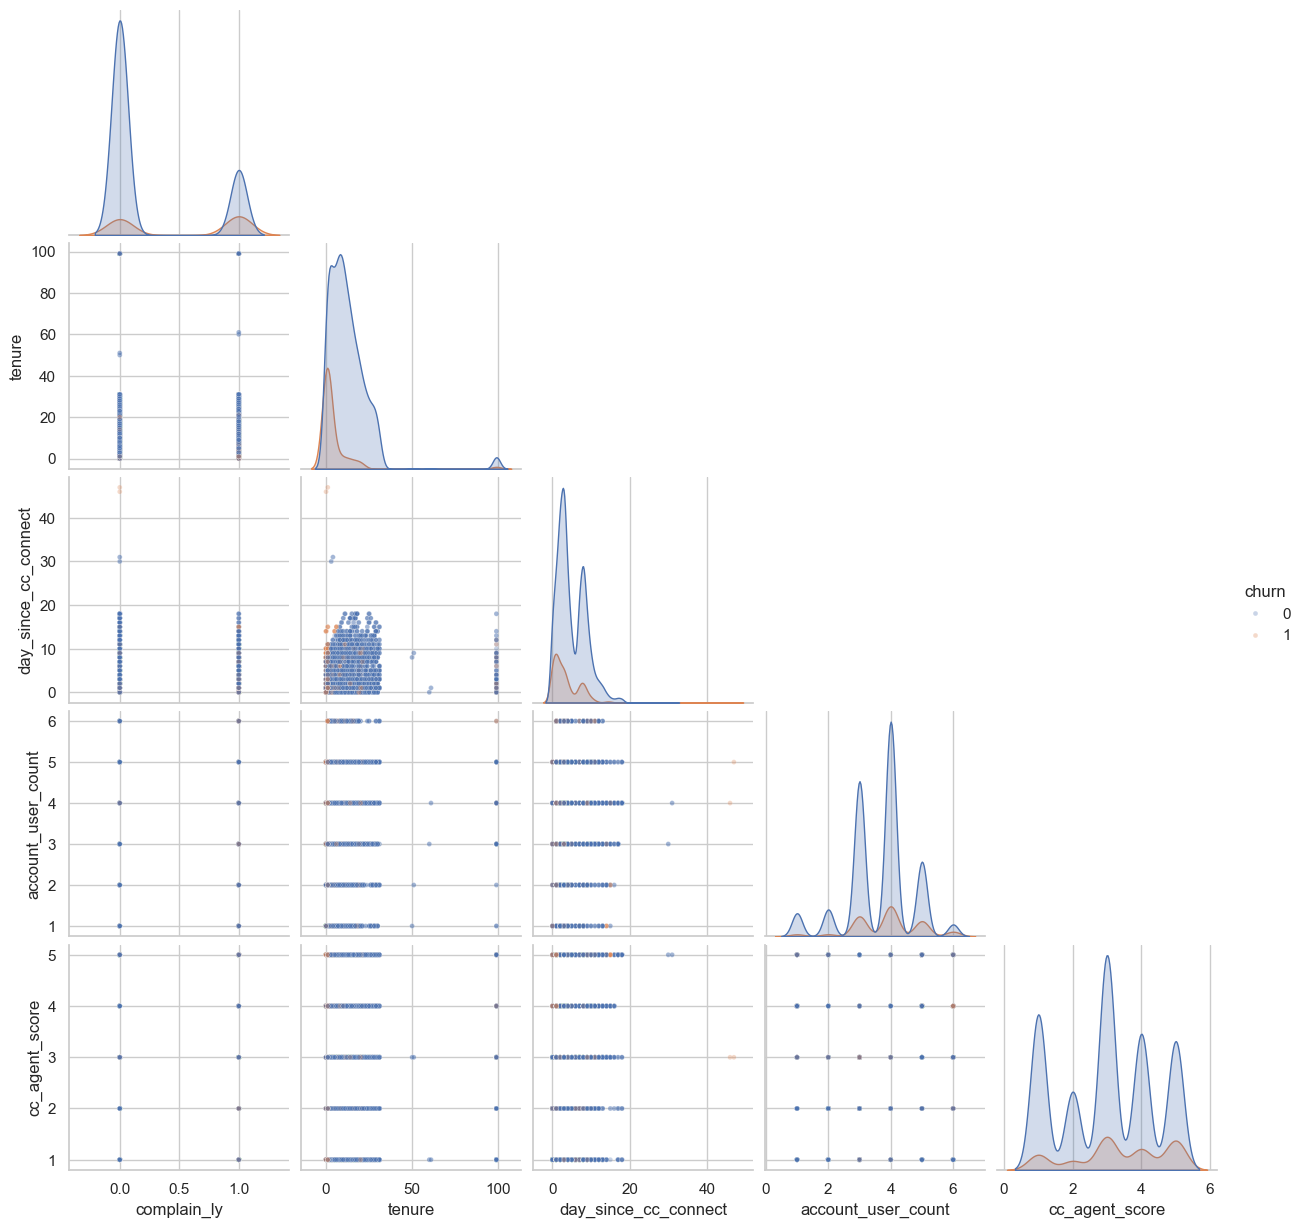

In [17]:
# To Observe class separation, clustering, and possible interactions.
top_vars = df_eda[num_var].corrwith(df_eda[TARGET_COL]).abs().nlargest(5).index.tolist() # select top 5 correlated numerical features with target

sns.pairplot(
    df_eda[top_vars + [TARGET_COL]].dropna(),
    hue=TARGET_COL,
    diag_kind="kde",
    corner=True
    ,plot_kws={"alpha": 0.3, "s": 12} # adjust point transparency and size for better visibility
)
plt.show()


**Pairplot Observation**

| Key Observation                                           | Impact   | Interpretation                                          |
| --------------------------------------------------------- | -------- | ------------------------------------------------------- |
| Churned customers cluster at shorter tenure periods.      | Strong   | New customers face higher churn risk.                   |
 | Complaint history shows noticeable class separation.      | Strong   | Complaints are associated with churn.                   |
| Contact recency and account size show partial separation. | Moderate | Customer engagement may contribute to churn prediction. |
 | Agent scores show substantial class overlap.              | Weak     | Limited standalone differentiation.                     |


##### Categorical Interaction - 3D Cube Plot

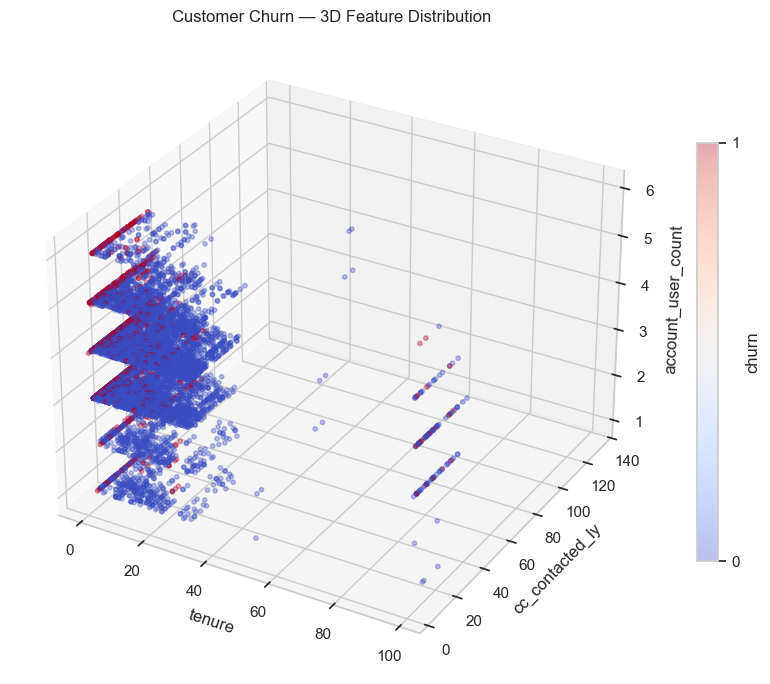

In [18]:
# Multivariate Analysis — 3D Cube Plot

cols = ["tenure", "cc_contacted_ly", "account_user_count"] # These
plot_df = df_eda[cols + [TARGET_COL]].dropna()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    plot_df[cols[0]], plot_df[cols[1]], plot_df[cols[2]],
    c=plot_df[TARGET_COL], cmap="coolwarm", alpha=0.35, s=10
)

ax.set(xlabel=cols[0], ylabel=cols[1], zlabel=cols[2],
       title="Customer Churn — 3D Feature Distribution")

fig.colorbar(scatter, ax=ax, label=TARGET_COL, ticks=[0, 1], shrink=0.65)
plt.tight_layout()
plt.show()


**3D Plot Observation**

 These three variables were selected to explore the combined effects of customer lifecycle, contact frequency, and account size, rather than simply choosing the three strongest individual predictors.

| Key Observation                                           | Impact   | Interpretation                                          |
 | --------------------------------------------------------- | -------- | ------------------------------------------------------- |
| Churned customers concentrate at shorter tenure.          | Strong   | Early customer lifecycle is associated with churn.      |
 | Contact frequency varies across both churn classes.       | Weak     | Contact frequency alone provides limited separation.    |
| Account sizes overlap considerably across churn classes.  | Weak     | No distinct 3D churn clusters are evident.              |

##### Overall Multivariate Summary

- Complaint history (+0.25) and tenure (-0.23) show the strongest correlations with churn.
- Account size, agent score, and contact recency demonstrate weaker but potentially useful associations.
- Low correlations among predictors suggest limited multicollinearity.
- Pairplot analysis confirms clearer churn separation for tenure and complaints, with substantial overlap across other variables.
- 3D analysis shows churn concentration among newer customers but no distinct clusters across tenure, contact frequency, and account size.
- Combined predictors may improve churn classification beyond individual variables.

**Strategic Implication**

Customer churn is primarily associated with customer lifecycle and complaint history, supported by engagement and account characteristics. Retention strategies should prioritize new customers and those reporting complaints, while machine learning models should evaluate combined feature effects to identify high-risk customers more accurately.

---

### Data Preprocessing

EDA findings guide preprocessing to improve data quality while preserving useful information.

| Finding | Action | Purpose |
|---|---|---|
| Missing values | Impute with median/mode | Retain records |
| Inconsistent labels | Standardize categories | Avoid duplicates |
| `accountid` is an identifier | Exclude from model features; retain for customer segmentation | Avoid identifier-based predictions while enabling segment-level analysis |
| Outliers | Retain initially | Preserve valid variation |
| Skewed data | Transform if needed | Improve model fit |
| Categorical features | One-hot encode | Enable model training |
| Different scales | Standardize | Support scale-sensitive models |
| Class imbalance | Stratify train/test split | Preserve class proportions |
| Data leakage risk | Fit preprocessing on training data only | Ensure fair evaluation |

Use `df_clean` with corrected numerical values; keep the original dataset unchanged.

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

#### Finalize the Cleaned Dataset

The categorical plots revealed additional inconsistent labels in `account_segment`. We should correct these alongside `gender` and `login_device` before splitting the dataset.

In [19]:
# Finalize categorical cleaning.
df_model = df_clean.copy()
cat_cols = df_model.select_dtypes(include=["object", "string"]).columns
df_model[cat_cols] = df_model[cat_cols].apply(lambda s: s.str.strip().str.lower())

# Correct inconsistent labels.
fixes = {
    "gender": {"m": "male", "f": "female"},
    "login_device": {"&&&&": "others"},
    "account_segment": {"regular +": "regular plus", "super +": "super plus"}
}
df_model = df_model.replace(fixes)

# Verify cleaned categories in one table.
cols = list(fixes)
summary = pd.concat({c: df_model[c].value_counts(dropna=False) for c in cols},
                    names=["Variable", "Category"]).reset_index(name="Count")
display(summary)

,Variable,Category,Count
0,gender,male,6704
1,gender,female,4448
2,gender,NaN,108
3,login_device,mobile,7482
4,login_device,computer,3018
5,login_device,others,539
6,login_device,NaN,221
7,account_segment,regular plus,4124
8,account_segment,super,4062
9,account_segment,hni,1639


In [20]:
# Post-Preprocessing Validation: Unique Categorical Values and Numerical Ranges
# Categorical features: unique values
for col in df_model.select_dtypes(exclude="number"):
    print(f"{col}: {sorted(df_model[col].dropna().astype(str).unique())}")

# Numerical features: minimum and maximum values
display(df_model.select_dtypes(include="number").agg(["min","max"]).T)

payment: ['cash on delivery', 'credit card', 'debit card', 'e wallet', 'upi']
gender: ['female', 'male']
account_segment: ['hni', 'regular', 'regular plus', 'super', 'super plus']
marital_status: ['divorced', 'married', 'single']
login_device: ['computer', 'mobile', 'others']


,min,max
accountid,20000.00,31259.00
churn,0.00,1.00
tenure,0.00,99.00
city_tier,1.00,3.00
cc_contacted_ly,4.00,132.00
service_score,0.00,5.00
account_user_count,1.00,6.00
cc_agent_score,1.00,5.00
rev_per_month,1.00,140.00
complain_ly,0.00,1.00


**Observation**: Following preprocessing, the dataset contains five categorical predictors with defined categories and numerical variables within their observed ranges, providing a consistent foundation for model development.

## <span style="color:#1976D2;">Model preparation and leakage-safe preprocessing</span>

The EDA above informs feature cleaning. The modelling pipeline below performs imputation and encoding **within training folds**. This avoids fitting preprocessing on held-out observations.

In [21]:
%%writefile scripts/preprocessing.py
"""Shared, serializable preprocessing for training and ChurnGuard inference."""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERIC_FIX_COLS = ("tenure", "account_user_count", "rev_per_month", "rev_growth_yoy", "coupon_used_for_payment", "day_since_cc_connect", "cashback")
DISCRETE_CANDIDATES = ("account_user_count", "complain_ly")
CATEGORY_MAPS = {
    "gender": {"m": "male", "f": "female"},
    "login_device": {"&&&&": "others"},
    "account_segment": {"regular +": "regular plus", "super +": "super plus"},
}

class NormalizeChurnFeatures(BaseEstimator, TransformerMixin):
    """Normalize numeric and categorical features while preserving column names."""

    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Expected a pandas DataFrame")
        self.feature_names_in_ = list(X.columns)
        return self

    def transform(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Expected a pandas DataFrame")

        missing = set(self.feature_names_in_) - set(X.columns)
        if missing:
            raise ValueError(f"Missing required features: {sorted(missing)}")

        out = X.loc[:, self.feature_names_in_].copy()

        # Convert numeric text
        for col in NUMERIC_FIX_COLS:
            if col in out:
                out[col] = pd.to_numeric(out[col], errors="coerce")

        # Normalize categorical values
        for col in out.columns:
            if col not in NUMERIC_FIX_COLS and (
                pd.api.types.is_object_dtype(out[col])
                or pd.api.types.is_string_dtype(out[col])
            ):
                out[col] = (
                    out[col].astype("string")
                    .str.strip()
                    .str.lower()
                    .astype(object)
                )

        # Standardize categorical labels
        for col, mapping in CATEGORY_MAPS.items():
            if col in out:
                out[col] = out[col].replace(mapping)

        # Ensure compatibility with sklearn SimpleImputer
        out = out.astype(object).replace({pd.NA: np.nan})

        return out


def build_preprocessor(X):
    """Create unfitted preprocessing; call on the raw feature DataFrame."""
    num_cols = list(dict.fromkeys(list(X.select_dtypes(include="number").columns) + [c for c in NUMERIC_FIX_COLS if c in X.columns]))
    cat_cols = [c for c in X.columns if c not in num_cols]
    discrete_cols = [c for c in DISCRETE_CANDIDATES if c in num_cols]
    continuous_cols = [c for c in num_cols if c not in discrete_cols]
    columns = ColumnTransformer([
        ("continuous", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), continuous_cols),
        ("discrete", SimpleImputer(strategy="most_frequent"), discrete_cols),
        ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ])
    return Pipeline([("normalize", NormalizeChurnFeatures()), ("columns", columns)])


Overwriting scripts/preprocessing.py


In [22]:
from scripts.preprocessing import build_preprocessor # import the build_preprocessor function from preprocessing.py

# Set the target column and identifier column for the dataset.
TARGET_COL = "churn"
id_cols = "accountid"

# Split before fitting imputation, encoding or scaling.
X = df.drop(columns=[TARGET_COL, id_cols])
y = df[TARGET_COL]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Retain account IDs for campaign targeting.
train_accounts = df.loc[X_train.index, id_cols].copy()
test_accounts = df.loc[X_test.index, id_cols].copy()

# Apply preprocessing to the training data and retain the fitted preprocessor for later use on new data.
preprocessor = build_preprocessor(X_train)
assert set(X_train.index).isdisjoint(X_test.index)

print(f"Dataset: ***/data/{FILE_PATH.name} | Train: {len(X_train):,} | Test: {len(X_test):,}")
print(f"Features: {X_train.shape[1]} | Churn: {y_train.mean():.2%} train, {y_test.mean():.2%} test")
print("Shared preprocessing module ready (unfitted).")



Dataset: ***/data/Customer Churn Data.xlsx | Train: 9,008 | Test: 2,252
Features: 17 | Churn: 16.84% train, 16.83% test
Shared preprocessing module ready (unfitted).


## <span style="color:#1976D2;">Model Building and Evaluation </span>

---
### Models and metric choice



Building on Milestone 1, nine classification models are evaluated to predict customer churn.

| Model | Purpose | Source |
|---|---|---|
| Logistic Regression | Linear baseline | Milestone 1 |
| Decision Tree | Nonlinear patterns | Milestone 1 |
| Random Forest | Ensemble stability | Milestone 1 |
| Gradient Boosting | Sequential learning | Milestone 1 |
| XGBoost | Optimized boosting | Milestone 1 |
| KNN | Distance-based classification | New |
| Gaussian Naive Bayes | Probabilistic classification | New |
| SVM (RBF) | Nonlinear decision boundaries | New |
| Extra Trees | Randomized ensemble | New |

**F1** is the primary selection metric due to churn imbalance (~16.8%), supported by precision, recall, PR-AUC, ROC-AUC and confusion matrices. Preprocessing is fitted within each training fold.

All models use consistent preprocessing and stratified cross-validation to ensure fair comparison. The best-performing model will be considered for integration with the existing ChurnGuard automated prediction pipeline.

---

###  Helper Function

In [23]:
# Train models using identical preprocessing.
def train_models(models, preprocessor, X_train, y_train):
    """Fit each model with a fresh copy of the shared preprocessing pipeline.
       Displays training progress, and returns a dictionary of trained models for evaluation and comparison.
    """
    trained = {}
    for name, model in models.items():
        # Keep preprocessing and classifier instances independent for each model.
        pipeline = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("classifier", clone(model)),
        ])
        trained[name] = pipeline.fit(X_train, y_train)
        print(f"{name}: Training completed")
    return trained

In [24]:
# Evaluate the selected model on the held-out test set ONLY after model selection.
def evaluate_final_model(name, model, X_test, y_test):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    result = pd.DataFrame([{
        "Model": name, "Dataset": "Test",
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob),
    }])
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0, 1], display_labels=["Retained", "Churned"],
        cmap="Blues", colorbar=False
    )
    plt.title(f"Final held-out test: {name}")
    plt.show()
    return result

In [25]:
# Tune each model with stratified cross-validation and rank by validation F1.

def tune_models(models, tuning_params, preprocessor, X_train, y_train):
    """Return the best fitted model and CV summary for each classifier."""
    # Preserve churn proportions in each fold.
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    tuned_models, results = {}, []
    total_models = len(models)
    overall_start = time.perf_counter()

    def log(message):
        timestamp = datetime.now().strftime("%H:%M:%S")
        print(f"[{timestamp}] {message}", flush=True)

    log(f"Starting hyperparameter tuning: {total_models} models")
    log(f"Training records: {len(X_train):,} | Features: {X_train.shape[1]}")
    log("Selection metric: F1 | Cross-validation: 5 folds")
    print(flush=True)

    for index, (name, model) in enumerate(models.items(), start=1):
        start_time = time.perf_counter()
        n_candidates = min(20, len(ParameterGrid(tuning_params[name])))

        log(f"[{index}/{total_models}] Tuning {name}")
        log(f"  Search candidates: {n_candidates} | CV fits: {n_candidates * 5}")

        # Clone preprocessing and classifier so each search is independent.
        pipeline = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("classifier", clone(model)),
        ])

        # Search parameter combinations using F1 score.
        search = RandomizedSearchCV(
            pipeline,
            tuning_params[name],
            n_iter=n_candidates,
            scoring="f1",
            cv=cv,
            n_jobs=1,
            random_state=42,
            verbose=1,
            refit=True,
            error_score="raise",
        )

        log(f"  {name}: Running hyperparameter search...")
        search.fit(X_train, y_train)

        tuned_models[name] = search.best_estimator_
        results.append({
            "Model": name,
            "CV F1": search.best_score_,
            "Best Parameters": search.best_params_,
        })

        elapsed = time.perf_counter() - start_time

        log(f"  {name}: Completed | Best CV F1={search.best_score_:.4f}")
        log(f"  Best parameters: {search.best_params_}")
        log(f"  Execution time: {elapsed:.1f}s")

        # Add a blank line between model tuning results.
        print(flush=True)

    # Summarize models from highest to lowest cross-validation F1.
    summary = (
        pd.DataFrame(results)
        .sort_values("CV F1", ascending=False)
        .set_index("Model")
    )

    log(f"All tuning completed in {(time.perf_counter() - overall_start) / 60:.1f} minutes")
    log(f"Best tuned model: {summary.index[0]} | CV F1={summary.iloc[0]['CV F1']:.4f}")

    display(summary.round(3))
    return tuned_models, summary



In [26]:
# Compare models with stratified CV and plot out-of-fold confusion matrices.
def evaluate_cv(models, preprocessor, X_train, y_train):
    """Rank models by 5-fold F1 score and show their out-of-fold confusion matrices."""
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scoring = {
        "Precision": "precision", "Recall": "recall", "F1": "f1",
        "ROC-AUC": "roc_auc", "PR-AUC": "average_precision",
    }
    results, matrices = [], {}
    total_models = len(models)

    def log(message):
        timestamp = datetime.now().strftime("%H:%M:%S")
        print(f"[{timestamp}] {message}", flush=True)

    log(f"Starting baseline evaluation: {total_models} models, 5-fold stratified CV")
    log(f"Training records: {len(X_train):,} | Features: {X_train.shape[1]}")
    log("Evaluation metrics: Precision, Recall, F1, ROC-AUC, PR-AUC")

    for index, (name, model) in enumerate(models.items(), start=1):
        start_time = time.perf_counter()
        log(f"[{index}/{total_models}] Evaluating {name}")

        # Use existing pipelines as-is; otherwise add shared preprocessing.
        pipeline = clone(model) if isinstance(model, Pipeline) else Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("classifier", clone(model)),
        ])

        log(f"  {name}: Running 5-fold cross-validation...")
        scores = cross_validate(
            pipeline, X_train, y_train,
            cv=cv, scoring=scoring, n_jobs=1, error_score="raise"
        )

        # Out-of-fold predictions keep each row unseen during its prediction.
        log(f"  {name}: Generating out-of-fold predictions...")
        pred = cross_val_predict(
            pipeline, X_train, y_train, cv=cv, n_jobs=1
        )

        results.append({
            "Model": name,
            **{metric: scores[f"test_{metric}"].mean() for metric in scoring},
            "PR-AUC SD": scores["test_PR-AUC"].std(),
        })
        matrices[name] = confusion_matrix(y_train, pred, labels=[0, 1])

        elapsed = time.perf_counter() - start_time
        log(
            f"  {name}: Completed | "
            f"F1={results[-1]['F1']:.4f} | "
            f"PR-AUC={results[-1]['PR-AUC']:.4f} | "
            f"Time={elapsed:.1f}s"
        )

    # Add a blank line between model evaluations.
        print(flush=True)

    # Sort models by mean cross-validation F1 score.
    cv_df = (
        pd.DataFrame(results)
        .sort_values("F1", ascending=False)
        .set_index("Model")
    )

    log("All baseline evaluations completed. Displaying results.")
    display(cv_df.T.round(4))

    # Plot out-of-fold confusion matrices in a compact grid.
    n_models = len(cv_df)
    n_cols = 3
    n_rows = (n_models + n_cols - 1) // n_cols

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(15, 4 * n_rows),
        squeeze=False
    )

    for ax, name in zip(axes.ravel(), cv_df.index):
        ConfusionMatrixDisplay(
            confusion_matrix=matrices[name],
            display_labels=["Retained", "Churned"]
        ).plot(ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(name)

    # Hide unused subplot axes.
    for ax in axes.ravel()[n_models:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    log(f"Best baseline model by F1: {cv_df.index[0]}")
    return cv_df


---

### Configure nine baseline models

In [27]:
# Six complementary model families; churn weighting is computed from training labels only.
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=1),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "SVM (RBF)": SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=1),
    "XGBoost": XGBClassifier(n_estimators=200, scale_pos_weight=scale_pos_weight, eval_metric="logloss", random_state=42, n_jobs=1),
}

In [28]:
# Train Baseline Models
trained_models = train_models(models, preprocessor, X_train, y_train)

# Summarize trained models.
model_summary = pd.DataFrame({
    "Model": list(trained_models),
    "Training Records": len(X_train),
    "Features": X_train.shape[1],
    "Status": "Trained"
})

display(model_summary)


Logistic Regression: Training completed
Decision Tree: Training completed
Gradient Boosting: Training completed
Extra Trees: Training completed
KNN: Training completed
Naive Bayes: Training completed
SVM (RBF): Training completed
Random Forest: Training completed
XGBoost: Training completed


,Model,Training Records,Features,Status
0,Logistic Regression,9008,17,Trained
1,Decision Tree,9008,17,Trained
2,Gradient Boosting,9008,17,Trained
3,Extra Trees,9008,17,Trained
4,KNN,9008,17,Trained
5,Naive Bayes,9008,17,Trained
6,SVM (RBF),9008,17,Trained
7,Random Forest,9008,17,Trained
8,XGBoost,9008,17,Trained


---
### Baseline performance — five-fold stratified cross-validation

[23:57:46] Starting baseline evaluation: 9 models, 5-fold stratified CV
[23:57:46] Training records: 9,008 | Features: 17
[23:57:46] Evaluation metrics: Precision, Recall, F1, ROC-AUC, PR-AUC
[23:57:46] [1/9] Evaluating Logistic Regression
[23:57:46]   Logistic Regression: Running 5-fold cross-validation...
[23:57:46]   Logistic Regression: Generating out-of-fold predictions...
[23:57:46]   Logistic Regression: Completed | F1=0.5365 | PR-AUC=0.6155 | Time=0.8s

[23:57:46] [2/9] Evaluating Decision Tree
[23:57:46]   Decision Tree: Running 5-fold cross-validation...
[23:57:47]   Decision Tree: Generating out-of-fold predictions...
[23:57:47]   Decision Tree: Completed | F1=0.8194 | PR-AUC=0.7014 | Time=0.9s

[23:57:47] [3/9] Evaluating Gradient Boosting
[23:57:47]   Gradient Boosting: Running 5-fold cross-validation...
[23:57:52]   Gradient Boosting: Generating out-of-fold predictions...
[23:57:56]   Gradient Boosting: Completed | F1=0.6862 | PR-AUC=0.8027 | Time=8.9s

[23:57:56] [4/9] E

Model,Extra Trees,XGBoost,Random Forest,Decision Tree,KNN,Gradient Boosting,SVM (RBF),Logistic Regression,Naive Bayes
Precision,0.98,0.91,0.97,0.82,0.88,0.81,0.53,0.41,0.42
Recall,0.88,0.91,0.81,0.82,0.75,0.59,0.85,0.78,0.63
F1,0.93,0.91,0.88,0.82,0.81,0.69,0.65,0.54,0.50
ROC-AUC,1.00,0.99,0.99,0.89,0.97,0.93,0.92,0.85,0.78
PR-AUC,0.99,0.97,0.97,0.70,0.87,0.80,0.76,0.62,0.45
PR-AUC SD,0.00,0.01,0.01,0.01,0.01,0.03,0.02,0.02,0.04


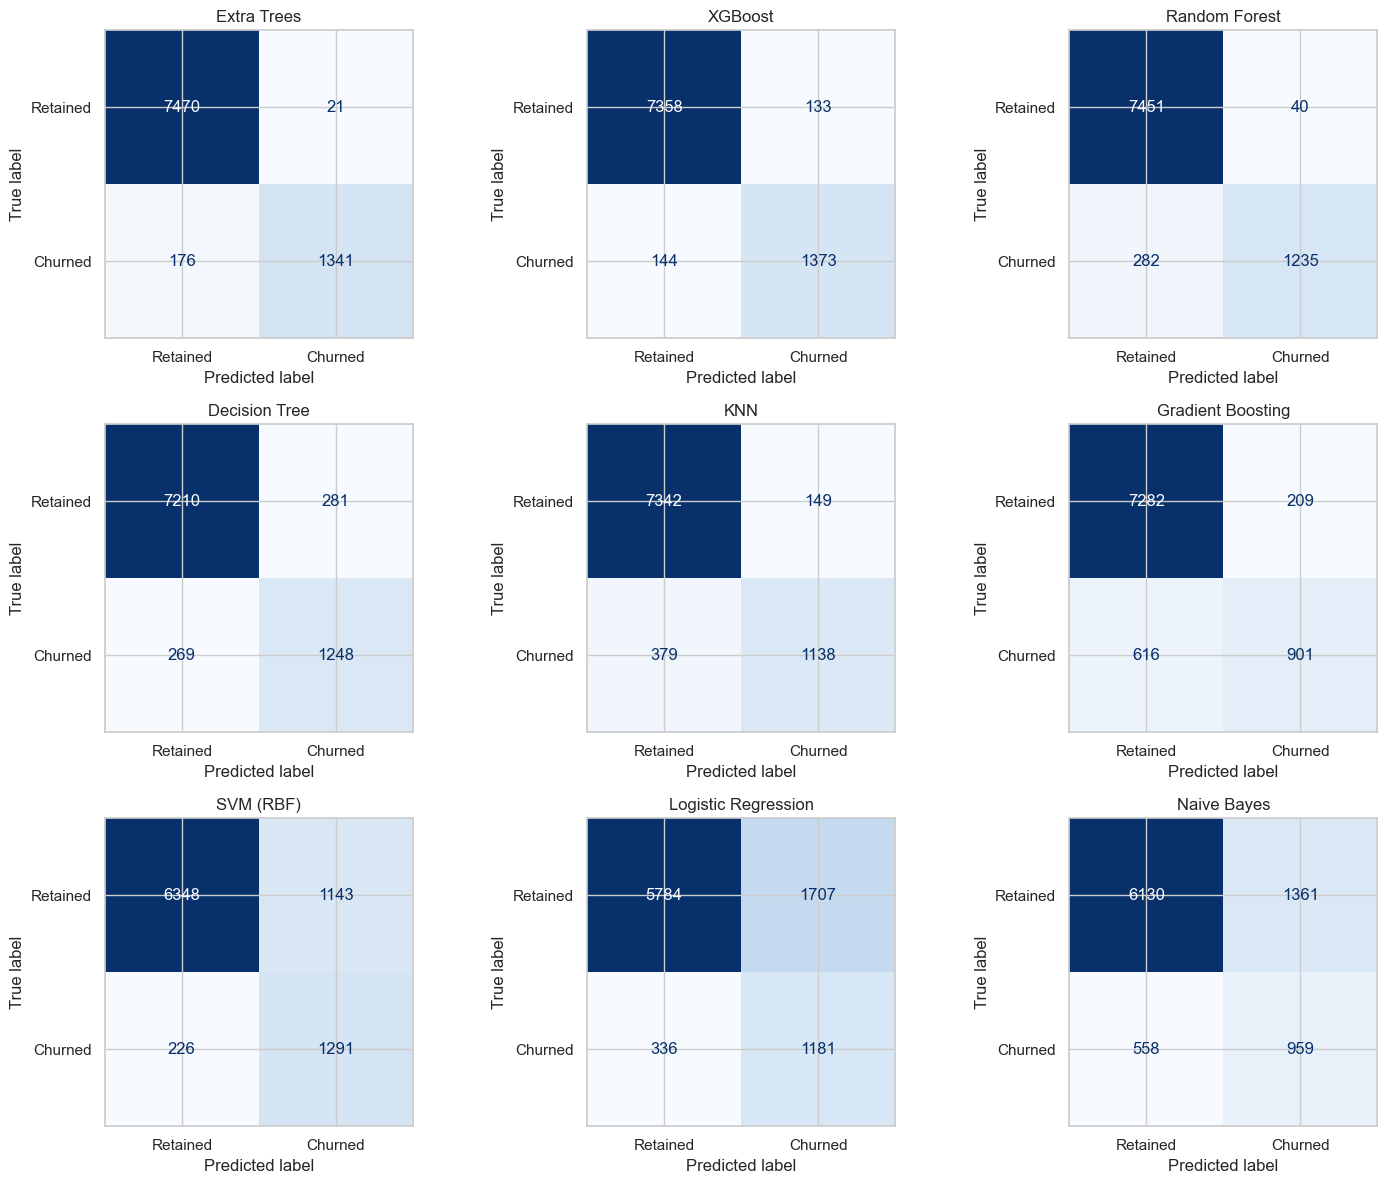

[23:58:56] Best baseline model by F1: Extra Trees


,Precision,Recall,F1,ROC-AUC,PR-AUC,PR-AUC SD
Model,,,,,,
Extra Trees,0.98,0.88,0.93,1.00,0.99,0.00
XGBoost,0.91,0.91,0.91,0.99,0.97,0.01
Random Forest,0.97,0.81,0.88,0.99,0.97,0.01
Decision Tree,0.82,0.82,0.82,0.89,0.70,0.01
KNN,0.88,0.75,0.81,0.97,0.87,0.01
Gradient Boosting,0.81,0.59,0.69,0.93,0.80,0.03
SVM (RBF),0.53,0.85,0.65,0.92,0.76,0.02
Logistic Regression,0.41,0.78,0.54,0.85,0.62,0.02
Naive Bayes,0.42,0.63,0.50,0.78,0.45,0.04


In [29]:
# Evaluate baseline models using only the training set (no test-set inspection).
baseline_cv_results = evaluate_cv(
    trained_models, preprocessor, X_train, y_train
)

display(baseline_cv_results.round(4))

**Baseline Model Evaluation — Observations**

- Extra Trees achieved the strongest overall performance, balancing precision and recall with minimal classification errors, and correctly identifying 1,341 churners, with only 21 retained customers incorrectly classified as churners and 176 churners missed. 

- XGBoost and Random Forest also performed well. XGBoost identified more churners (1,373) but incorrectly classified 133 retained customers while Random Forest missed 282 churners.

- The remaining models showed higher classification errors. Extra Trees, XGBoost, and Random Forest are the leading candidates for hyperparameter tuning.

## <span style="color:#1976D2;">Model Improvement, Comparison and Final Selection</span>

All nine models undergo hyperparameter tuning using 5-fold stratified cross-validation, with F1 as the primary selection metric. The highest cross-validation score may be optimistic due to model selection. The untouched test set will therefore be used only to evaluate the final selected model.

---
### Hyperparameter Tuning

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

#### Hyperparameter tuning rationale

- **Extra Trees / Random Forest:** number of trees controls ensemble stability and compute cost; maximum depth and minimum leaf size regulate complexity and overfitting.
- **Gradient Boosting / XGBoost:** learning rate, depth and estimator count control boosting strength; XGBoost subsampling and feature sampling reduce variance.
- **Logistic Regression / SVM:** `C` tests stronger versus weaker regularisation; SVM `gamma` controls the RBF decision boundary.
- **KNN:** neighbour count trades local sensitivity against smoothing; weighting and distance metric test alternative neighbourhood definitions.
- **Naive Bayes:** variance smoothing stabilises probabilities for low-variance features.

Search ranges are intentionally modest to limit computation; **up to 20 random combinations** are assessed per model with stratified five-fold CV. Model selection is based on training-fold CV F1, not held-out test scores.

In [30]:
# Define hyperparameter search spaces for all nine classifiers.
tuning_params = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10],
        "classifier__class_weight": [None, "balanced"]
    },
    "Decision Tree": {
        "classifier__max_depth": [None, 5, 10, 20],
        "classifier__min_samples_leaf": [1, 3, 5]
    },
    "Gradient Boosting": {
        "classifier__n_estimators": [100, 200],
        "classifier__learning_rate": [0.03, 0.1],
        "classifier__max_depth": [2, 3]
    },
    "Extra Trees": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_leaf": [1, 3]
    },
    "KNN": {
        "classifier__n_neighbors": [3, 5, 9, 15, 25],
        "classifier__weights": ["uniform", "distance"],
        "classifier__p": [1, 2]
    },
    "Naive Bayes": {
        "classifier__var_smoothing": [1e-11, 1e-10, 1e-9, 1e-8, 1e-7]
    },
    "SVM (RBF)": {
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", 0.01, 0.1]
    },
    "Random Forest": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [None, 8, 15],
        "classifier__min_samples_leaf": [1, 3, 5]
    },
    "XGBoost": {
        "classifier__n_estimators": [100, 200, 350],
        "classifier__max_depth": [3, 5, 7],
        "classifier__learning_rate": [0.03, 0.1],
        "classifier__subsample": [0.8, 1.0],
        "classifier__colsample_bytree": [0.8, 1.0]
    }
}

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

#### Tune models

In [31]:
# Train tuned Models
tuned_models, tuning_results = tune_models(
    models, tuning_params, preprocessor, X_train, y_train
)

[23:58:56] Starting hyperparameter tuning: 9 models
[23:58:56] Training records: 9,008 | Features: 17
[23:58:56] Selection metric: F1 | Cross-validation: 5 folds

[23:58:56] [1/9] Tuning Logistic Regression
[23:58:56]   Search candidates: 8 | CV fits: 40
[23:58:56]   Logistic Regression: Running hyperparameter search...
Fitting 5 folds for each of 8 candidates, totalling 40 fits
[23:58:59]   Logistic Regression: Completed | Best CV F1=0.5370
[23:58:59]   Best parameters: {'classifier__class_weight': 'balanced', 'classifier__C': 0.1}
[23:58:59]   Execution time: 2.8s

[23:58:59] [2/9] Tuning Decision Tree
[23:58:59]   Search candidates: 12 | CV fits: 60
[23:58:59]   Decision Tree: Running hyperparameter search...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
[23:59:04]   Decision Tree: Completed | Best CV F1=0.8194
[23:59:04]   Best parameters: {'classifier__min_samples_leaf': 1, 'classifier__max_depth': None}
[23:59:04]   Execution time: 4.7s

[23:59:04] [3/9] Tuning Gra

,CV F1,Best Parameters
Model,,
Extra Trees,0.94,"{'classifier__n_estimators': 200, 'classifier_..."
KNN,0.92,"{'classifier__weights': 'distance', 'classifie..."
XGBoost,0.91,"{'classifier__subsample': 0.8, 'classifier__n_..."
SVM (RBF),0.90,"{'classifier__gamma': 0.1, 'classifier__C': 10}"
Random Forest,0.89,"{'classifier__n_estimators': 100, 'classifier_..."
Decision Tree,0.82,"{'classifier__min_samples_leaf': 1, 'classifie..."
Gradient Boosting,0.72,"{'classifier__n_estimators': 200, 'classifier_..."
Logistic Regression,0.54,"{'classifier__class_weight': 'balanced', 'clas..."
Naive Bayes,0.50,{'classifier__var_smoothing': 1e-11}


**Hyperparameter Tuning — Observations**

Extra Trees retained the highest F1 score after tuning, confirming its strong baseline performance. KNN and SVM showed notable improvements, moving ahead of several ensemble models, while XGBoost remained competitive.

Extra Trees is the leading candidate for final model selection, subject to comparison with baseline results and evaluation on the untouched test set.

---
### Baseline vs tuned comparison (training data only)

In [32]:
# Compare baseline and tuned cross-validation F1 scores without using test data.
comparison = pd.DataFrame({
    "Baseline F1": baseline_cv_results["F1"],
    "Tuned F1": tuning_results["CV F1"],
})

# Calculate the improvement in F1 after hyperparameter tuning.
comparison["F1 Change"] = comparison["Tuned F1"] - comparison["Baseline F1"]

# Sort models by tuned cross-validation F1 score.
comparison = comparison.sort_values("Tuned F1", ascending=False)

display(comparison.round(4))

,Baseline F1,Tuned F1,F1 Change
Model,,,
Extra Trees,0.93,0.94,0.01
KNN,0.81,0.92,0.11
XGBoost,0.91,0.91,0.00
SVM (RBF),0.65,0.90,0.25
Random Forest,0.88,0.88,0.00
Decision Tree,0.82,0.82,0.00
Gradient Boosting,0.69,0.72,0.04
Logistic Regression,0.54,0.54,0.00
Naive Bayes,0.50,0.50,0.00


**Model Comparison — Observations**

Extra Trees maintained the highest F1 score after tuning, making its tuned version the leading candidate for final model selection. SVM and KNN achieved the largest improvements, while XGBoost remained competitive. Random Forest and Decision Tree showed little or no improvement. Based on the selection criteria, the tuned Extra Trees model will be selected for final evaluation on the untouched test set and, subject to satisfactory performance, deployment.

---
### Final model selection by tuning CV F1

In [33]:
# Rank tuned models by cross-validation F1 score.
cv_comparison = tuning_results[["CV F1"]].sort_values(
    "CV F1", ascending=False
)

display(cv_comparison.round(4))

# Select the best-performing tuned model.
best_model_name = cv_comparison.index[0]
best_model = tuned_models[best_model_name]

print(f"\nSelected Model: {best_model_name}")
print(f"CV F1: {cv_comparison.iloc[0]['CV F1']:.4f}")

,CV F1
Model,
Extra Trees,0.94
KNN,0.92
XGBoost,0.91
SVM (RBF),0.90
Random Forest,0.88
Decision Tree,0.82
Gradient Boosting,0.72
Logistic Regression,0.54
Naive Bayes,0.50



Selected Model: Extra Trees
CV F1: 0.9369


---
### Final held-out test evaluation (selected model only)

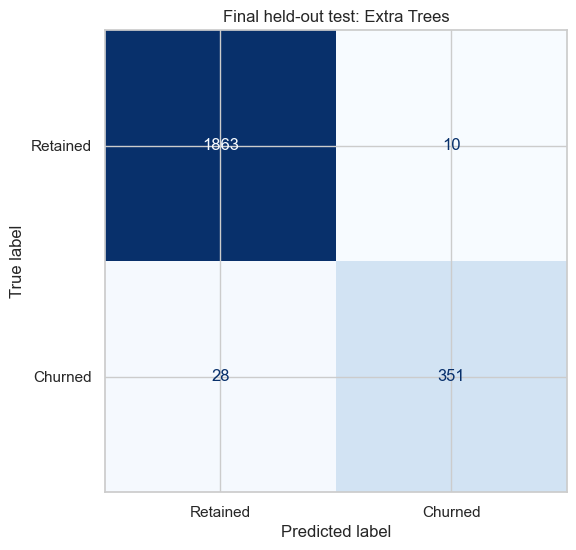

,,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Model,Dataset,,,,,,
Extra Trees,Test,0.98,0.97,0.93,0.95,1.00,0.99


In [34]:
# This cell evaluates the selected tuned model on the untouched test set, providing an independent assessment of its performance on unseen customer data.

final_results = evaluate_final_model(
    best_model_name, best_model, X_test, y_test
)

display(final_results.set_index(["Model", "Dataset"]).round(4))

**Final Test Evaluation — Observations**

The tuned Extra Trees model demonstrated strong performance on unseen data, confirming its ability to generalize beyond training. The confusion matrix shows 351 correctly identified churners, with only 28 churners missed and 10 retained customers incorrectly classified as churners.

The consistently high evaluation metrics support its selection as the final model for ChurnGuard deployment.

## <span style="color:#1976D2;">Model Export for Deployment</span> 

In [35]:
# Export the selected tuned model with its preprocessing pipeline.
model_filename = "churnguard_best_model.joblib"
model_path = MODELS_DIR / model_filename

MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(best_model, model_path)

# Display model details without exposing the full file path.
print(f"Selected Model: {best_model_name}")
print(f"Saved Model: ****/{MODELS_DIR.name}/{model_filename}")

Selected Model: Extra Trees
Saved Model: ****/models/churnguard_best_model.joblib


In [36]:
# Verify the exported model can be loaded and used for prediction.
loaded_model = joblib.load(model_path)

assert loaded_model.predict(X_test.head(5)).tolist() == \
       best_model.predict(X_test.head(5)).tolist()

print("Model export and reload verification successful.")

Model export and reload verification successful.


## <span style="color:#1976D2;">Customer Segmentation, Revenue Risk and Retention Economics</span>

This section brings the Milestone 1 segmentation and financial framework into Final Capstone, **recalculating all outputs using the selected tuned Extra Trees model**.

**Interpretation:** Probability-weighted revenue exposure is an estimate, not observed loss; campaign ROI uses assumed retention effectiveness and is not realised profit. Check probability calibration before using predicted probabilities for financial decisions.


---
### Account-level risk scoring and segmentation

Risk bands retained from Milestone 1: Low ≤30%, Moderate >30–60%, High >60–80%, Critical >80%. Account IDs are used for reporting and follow-up, **not as model predictors**.


In [37]:
test_accounts = df.loc[X_test.index, "accountid"]

# Generate account-level churn probabilities and risk segments.
def generate_churn_risk(model, X, accounts, y=None):
    """Return accounts ranked by predicted churn risk, with optional actual outcomes."""
    results = X[["account_segment", "tenure", "rev_per_month"]].copy()
    results.insert(0, "accountid", accounts.reindex(X.index))
    results["Churn Probability"] = model.predict_proba(X)[:, 1]

    # Group predicted probabilities into business-friendly risk bands.
    results["Risk Segment"] = pd.cut(
        results["Churn Probability"],
        bins=[-0.001, 0.30, 0.60, 0.80, 1.00],
        labels=["Low", "Moderate", "High", "Critical"],
    )

    if y is not None:
        results["Actual Churn"] = y.reindex(X.index)

    return results.sort_values("Churn Probability", ascending=False).reset_index(drop=True)

In [38]:
# Score and rank the held-out test accounts.
churn_risk = generate_churn_risk(best_model, X_test, test_accounts, y_test)

risk_sample = pd.concat([
    churn_risk.groupby("Risk Segment", observed=True).sample(n=1, random_state=42),
    churn_risk.drop(
        churn_risk.groupby("Risk Segment", observed=True).sample(n=1, random_state=42).index
    ).sample(n=12, random_state=42)
]).sample(frac=1, random_state=42)

display(risk_sample.round(4))

,accountid,account_segment,tenure,rev_per_month,Churn Probability,Risk Segment,Actual Churn
635,28435,Regular Plus,2,4,0.11,Low,0
397,23834,Super,5,9,0.34,Moderate,0
485,20055,Regular Plus,4,9,0.18,Low,0
305,29259,Super,1,3,0.69,High,1
1441,29778,Regular Plus,9,5,0.01,Low,0
1773,25564,Super,16,3,0.01,Low,0
1659,20048,Super,3,2,0.01,Low,0
871,21344,Super,7,3,0.05,Low,0
278,22194,Super,6,9,0.75,High,1
1471,24504,HNI,9,2,0.01,Low,0


---
### Risk distribution and account profiles


In [39]:
#  Summarize the Risk Distribution

churn_risk["Churn Probability"] = pd.to_numeric(
    churn_risk["Churn Probability"], errors="coerce"
)

churn_risk["rev_per_month"] = pd.to_numeric(
    churn_risk["rev_per_month"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

risk_summary = (
    churn_risk.groupby("Risk Segment", observed=True)
    .agg(
        Accounts=("accountid", "count"),
        Avg_Churn_Probability=("Churn Probability", "mean"),
        Avg_Monthly_Revenue=("rev_per_month", "mean")
    )
    .reindex(["Critical", "High", "Moderate", "Low"])
)

risk_summary["Accounts (%)"] = (
    risk_summary["Accounts"] / risk_summary["Accounts"].sum() * 100
)

display(risk_summary.round(2))

,Accounts,Avg_Churn_Probability,Avg_Monthly_Revenue,Accounts (%)
Risk Segment,,,,
Critical,247,0.93,7.73,10.97
High,94,0.71,7.15,4.17
Moderate,61,0.45,4.92,2.71
Low,1850,0.04,6.35,82.15


---
### Probability-weighted monthly revenue at risk

Monthly exposure = monthly revenue × Extra Trees churn probability. Segment shares are calculated on the **Milestone 2 test set**.


In [40]:
# Summarize monthly revenue exposure by churn-risk segment.

def analyze_revenue_risk(churn_risk):
    """Report revenue exposure and account shares by risk segment."""
    df = churn_risk.copy()
    risk_col = "Probability-Weighted Monthly Revenue at Risk"
    df[risk_col] = df["rev_per_month"] * df["Churn Probability"]

    # Aggregate account counts and revenue measures by segment.
    summary = (
        df.groupby("Risk Segment", observed=True)
        .agg(
            Accounts=("accountid", "count"),
            **{
                "Monthly Revenue": ("rev_per_month", "sum"),
                risk_col: (risk_col, "sum"),
                "Average Churn Probability": ("Churn Probability", "mean"),
            },
        )
        .reindex(["Critical", "High", "Moderate", "Low"])
    )

    # Calculate each segment's share of accounts and estimated revenue at risk.
    summary["Accounts (%)"] = summary["Accounts"] / len(df) * 100
    summary["Share of Estimated Revenue at Risk (%)"] = (
        summary[risk_col] / summary[risk_col].sum() * 100
    )

    # Add combined High and Critical figures for prioritization.
    priority = df[df["Risk Segment"].isin(["Critical", "High"])]
    summary.loc["High + Critical"] = {
        "Accounts": len(priority),
        "Monthly Revenue": priority["rev_per_month"].sum(),
        risk_col: priority[risk_col].sum(),
        "Average Churn Probability": priority["Churn Probability"].mean(),
        "Accounts (%)": len(priority) / len(df) * 100,
        "Share of Estimated Revenue at Risk (%)": (
            priority[risk_col].sum() / df[risk_col].sum() * 100
        ),
    }

    display(summary.round(2))
    return summary

In [41]:
# Revenue at Risk Summary
revenue_risk_summary = analyze_revenue_risk(churn_risk)

,Accounts,Monthly Revenue,Probability-Weighted Monthly Revenue at Risk,Average Churn Probability,Accounts (%),Share of Estimated Revenue at Risk (%)
Risk Segment,,,,,,
Critical,247,1840.00,1688.12,0.93,10.97,60.55
High,94,608.00,438.81,0.71,4.17,15.74
Moderate,61,251.00,115.10,0.45,2.71,4.13
Low,1850,10934.00,546.17,0.04,82.15,19.59
High + Critical,341,2448.00,2126.93,0.87,15.14,76.28


---
### Retention actions and account prioritisation


In [42]:
# Define retention actions.
retention_actions = {
    "Critical": "Immediate personalized outreach, complaint resolution and tailored retention incentives",
    "High": "Proactive engagement, targeted retention offers and loyalty incentives",
    "Moderate": "Preventive engagement and service improvement",
    "Low": "Routine monitoring and customer engagement"
}

In [43]:
# Rank accounts by churn risk and estimated monthly revenue exposure.
def prioritize_accounts_for_retention(churn_risk):
    """Prioritize accounts by risk segment and probability-weighted revenue."""
    df = churn_risk.copy()

    df["Probability-Weighted Monthly Revenue at Risk"] = (
        df["rev_per_month"] * df["Churn Probability"]
    )

    risk_order = {"Critical": 0, "High": 1, "Moderate": 2, "Low": 3}
    df["Retention Priority"] = df["Risk Segment"].astype(str).map(risk_order) + 1
    df["Recommended Action"] = df["Risk Segment"].astype(str).map(retention_actions)

    return (
        df.sort_values(
            ["Retention Priority", "Probability-Weighted Monthly Revenue at Risk"],
            ascending=[True, False]
        )
        .reset_index(drop=True)
    )

# Generate and review prioritized accounts.
retention_plan = prioritize_accounts_for_retention(churn_risk)
display(retention_plan.head(20).round(2))

,accountid,account_segment,tenure,rev_per_month,Churn Probability,Risk Segment,Actual Churn,Probability-Weighted Monthly Revenue at Risk,Retention Priority,Recommended Action
0,24998,Super Plus,6,136.00,0.88,Critical,1,120.36,1,"Immediate personalized outreach, complaint res..."
1,21250,Regular Plus,0,113.00,0.96,Critical,1,108.88,1,"Immediate personalized outreach, complaint res..."
2,24065,Regular Plus,1,114.00,0.93,Critical,1,106.38,1,"Immediate personalized outreach, complaint res..."
3,27767,Super,0,129.00,0.82,Critical,1,105.78,1,"Immediate personalized outreach, complaint res..."
4,28705,Regular Plus,1,22.00,0.97,Critical,1,21.32,1,"Immediate personalized outreach, complaint res..."
5,20260,Regular Plus,0,19.00,0.92,Critical,1,17.48,1,"Immediate personalized outreach, complaint res..."
6,28760,HNI,1,15.00,0.92,Critical,1,13.73,1,"Immediate personalized outreach, complaint res..."
7,26767,Regular Plus,6,14.00,0.93,Critical,1,13.04,1,"Immediate personalized outreach, complaint res..."
8,29646,Super,1,13.00,0.96,Critical,1,12.47,1,"Immediate personalized outreach, complaint res..."
9,29081,Super,1,13.00,0.94,Critical,1,12.21,1,"Immediate personalized outreach, complaint res..."


---
### Illustrative campaign costs, break-even and ROI sensitivity

The assumptions below are carried forward from Milestone 1 for comparability; the customer scores and exposure values are recalculated from Extra Trees. Scenarios are **illustrative**, not evidence that outreach changes customer behaviour.


In [44]:
# Define campaign assumptions.

retention_success_scenarios={
    "Conservative":{"Critical":0.15,"High":0.20},
    "Base Case":{"Critical":0.30,"High":0.40},
    "Optimistic":{"Critical":0.45,"High":0.60}
}

retention_offers={
    "Personalized Outreach":0.05,
    "Loyalty Reward":0.10,
    "Discount Voucher":0.15,
    "Cashback Incentive":0.25,
    "Premium Benefit":0.60
}

In [45]:
# Evaluate illustrative retention-offer ROI and break-even costs.

def evaluate_campaign_impact(retention_plan, months=12, margin=0.30):
    """Calculate illustrative ROI across three retention scenarios."""

    # Evaluate only the Critical- and High-risk accounts.
    df = retention_plan[retention_plan["Risk Segment"].isin(["Critical", "High"])]
    results = []

    # Compare each assumed retention-success scenario by risk segment.
    for scenario, rates in retention_success_scenarios.items():
        for segment, group in df.groupby("Risk Segment", observed=True):
            accounts = len(group)
            revenue = group["rev_per_month"].sum()

            # Estimate contribution from probability-weighted revenue exposure.
            contribution = (group["Probability-Weighted Monthly Revenue at Risk"].sum()    * rates[segment]     * months    * margin  )

            # Calculate cost, net benefit, and ROI for each offer.
            for offer, pct in retention_offers.items():
                cost = revenue * pct
                net = contribution - cost
                results.append([scenario, segment, offer, pct * 100, rates[segment] * 100, accounts, cost, contribution / accounts, net,  net / cost * 100, net > 0,])

    # Assign descriptive column names to the scenario results.
    columns = [
        "Scenario", "Risk Segment", "Retention Offer", "Offer (%)","Success Rate (%)", "Accounts", "Estimated Campaign Cost",
        "Break-even Cost/Account", "Estimated Net Benefit", "Illustrative ROI (%)", "Viable"]

    # Return the results rounded to two decimal places.
    return pd.DataFrame(results, columns=columns).round(2)


In [46]:
campaign_impact=evaluate_campaign_impact(retention_plan)
display(campaign_impact)

,Scenario,Risk Segment,Retention Offer,Offer (%),Success Rate (%),Accounts,Estimated Campaign Cost,Break-even Cost/Account,Estimated Net Benefit,Illustrative ROI (%),Viable
0,Conservative,High,Personalized Outreach,5.00,20.00,94,30.40,3.36,285.54,939.29,True
1,Conservative,High,Loyalty Reward,10.00,20.00,94,60.80,3.36,255.14,419.64,True
2,Conservative,High,Discount Voucher,15.00,20.00,94,91.20,3.36,224.74,246.43,True
3,Conservative,High,Cashback Incentive,25.00,20.00,94,152.00,3.36,163.94,107.86,True
4,Conservative,High,Premium Benefit,60.00,20.00,94,364.80,3.36,-48.86,-13.39,False
5,Conservative,Critical,Personalized Outreach,5.00,15.00,247,92.00,3.69,819.58,890.85,True
6,Conservative,Critical,Loyalty Reward,10.00,15.00,247,184.00,3.69,727.58,395.43,True
7,Conservative,Critical,Discount Voucher,15.00,15.00,247,276.00,3.69,635.58,230.28,True
8,Conservative,Critical,Cashback Incentive,25.00,15.00,247,460.00,3.69,451.58,98.17,True
9,Conservative,Critical,Premium Benefit,60.00,15.00,247,1104.00,3.69,-192.42,-17.43,False


---
### ROI sensitivity comparison

In [47]:
# ROI sensitivity comparison

roi_sensitivity=campaign_impact.pivot(
    index=["Risk Segment","Retention Offer","Offer (%)"],
    columns="Scenario",
    values="Illustrative ROI (%)"
).reset_index()

roi_sensitivity.columns.name=None
display(roi_sensitivity)

,Risk Segment,Retention Offer,Offer (%),Base Case,Conservative,Optimistic
0,Critical,Cashback Incentive,25.00,296.34,98.17,494.51
1,Critical,Discount Voucher,15.00,560.57,230.28,890.85
2,Critical,Loyalty Reward,10.00,890.85,395.43,1386.28
3,Critical,Personalized Outreach,5.00,1881.70,890.85,2872.56
4,Critical,Premium Benefit,60.00,65.14,-17.43,147.71
5,High,Cashback Incentive,25.00,315.71,107.86,523.57
6,High,Discount Voucher,15.00,592.86,246.43,939.29
7,High,Loyalty Reward,10.00,939.29,419.64,1458.93
8,High,Personalized Outreach,5.00,1978.57,939.29,3017.86
9,High,Premium Benefit,60.00,73.21,-13.39,159.82


---
### Top 5 segment-offer combinations by highest ROI

In [48]:
# Top 5 segment-offer combinations by highest ROI
top_5=(campaign_impact
    .sort_values("Illustrative ROI (%)",ascending=False)
    .drop_duplicates(["Risk Segment","Retention Offer"])
    .head(5)
    .reset_index(drop=True))

display(top_5)

,Scenario,Risk Segment,Retention Offer,Offer (%),Success Rate (%),Accounts,Estimated Campaign Cost,Break-even Cost/Account,Estimated Net Benefit,Illustrative ROI (%),Viable
0,Optimistic,High,Personalized Outreach,5.00,60.00,94,30.40,10.08,917.43,3017.86,True
1,Optimistic,Critical,Personalized Outreach,5.00,45.00,247,92.00,11.07,2642.75,2872.56,True
2,Optimistic,High,Loyalty Reward,10.00,60.00,94,60.80,10.08,887.03,1458.93,True
3,Optimistic,Critical,Loyalty Reward,10.00,45.00,247,184.00,11.07,2550.75,1386.28,True
4,Optimistic,High,Discount Voucher,15.00,60.00,94,91.20,10.08,856.63,939.29,True


---
### Business interpretation and validation requirements

- Prioritise High/Critical accounts using **current Extra Trees scores**, exposure and service context; do not reuse Milestone 1 account counts as updated results.
- Compare low-cost personalised outreach with more expensive rewards using estimated incremental contribution after costs.
- Run a controlled pilot with treatment and comparison groups to measure actual retention uplift, cost per additional customer retained and net incremental contribution.
- Monitor calibration, churn recall, false alerts, fairness, data quality and changes in the customer population.

**Important:** The same held-out set is used here for descriptive business analysis after final model evaluation. Do not tune the model or its threshold on this set and then claim it remains an untouched final test.


## <span style="color:#1976D2;">ChurnGuard Prediction, Notifications and Automation</span>

This section operationalises the **same tuned Extra Trees pipeline** used above. It documents batch scoring, the Streamlit interface, email notifications and scheduled execution **before** the management recommendations. The examples create local deployment assets; they do not send emails or publish an application during notebook execution.

---
### Export the prediction feature schema

Store the expected feature names, numerical defaults and categorical options with the fitted model. This ensures incoming prediction files are checked against the training schema.

In [49]:
# Define numeric and categorical features.
numeric = X_train.select_dtypes(include="number").columns.tolist()
categorical = X_train.select_dtypes(exclude="number").columns.tolist()

# Preserve feature order, default values and dropdown options.
schema = {
    "model_file": model_filename,
    "model_name": best_model_name,
    "features": X_train.columns.tolist(),
    "numeric": numeric,
    "defaults": X_train[numeric].median().fillna(0).to_dict(),
    "categories": {
        c: X_train[c].dropna().astype(str).unique().tolist()
        for c in categorical
    }
}

# Export the feature schema for automated prediction.
schema_path = MODELS_DIR / "feature_schema.json"
schema_path.write_text(json.dumps(schema, indent=2, default=str), encoding="utf-8")

print(f"Selected Model: {best_model_name}")
print(f"Saved Model: ****/{MODELS_DIR.name}/{model_filename}")
print(f"Saved Schema: ****/{MODELS_DIR.name}/{schema_path.name}")

# Verify deployment assets are saved together in the models directory.
assert model_path.parent.resolve() == MODELS_DIR.resolve()
assert schema_path.parent.resolve() == MODELS_DIR.resolve()
assert schema["model_file"] == model_path.name
assert (MODELS_DIR / schema["model_file"]).is_file()
assert json.loads(schema_path.read_text(encoding="utf-8"))["model_file"] == model_filename
print("Deployment model and feature schema paths verified.")


Selected Model: Extra Trees
Saved Model: ****/models/churnguard_best_model.joblib
Saved Schema: ****/models/feature_schema.json
Deployment model and feature schema paths verified.


---
### Customer prediction and risk classification

The batch script reads new CSV/XLSX files from `data_to_predict/`, validates the required inputs, applies the saved Extra Trees model, assigns churn-risk bands and writes account-level predictions. Use only records with the same feature definitions as training.

In [50]:
%%writefile scripts/predict_changed.py
"""Score new or modified customer datasets using the trained ChurnGuard model."""
import argparse
import io
import json
import os
import re
import subprocess
import sys
from pathlib import Path

import joblib
import pandas as pd

# Input location, validation rules and retention recommendations.
INPUT_DIR = Path('data_to_predict')
BOUNDS = {'tenure': (0, 99), 'city_tier': (1, 3), 'cc_contacted_ly': (4, 132), 'service_score': (0, 5), 'account_user_count': (1, 6), 'cc_agent_score': (1, 5), 'rev_per_month': (1, 140), 'complain_ly': (0, 1), 'rev_growth_yoy': (4, 28), 'coupon_used_for_payment': (0, 16), 'day_since_cc_connect': (0, 47), 'cashback': (0, 1997)}
CATEGORIES = {'payment': ['cash on delivery', 'credit card', 'debit card', 'e wallet', 'upi'], 'gender': ['female', 'male'], 'account_segment': ['hni', 'regular', 'regular plus', 'super', 'super plus'], 'marital_status': ['divorced', 'married', 'single'], 'login_device': ['computer', 'mobile', 'others']}
ACTIONS = {'Critical': 'Immediate personalized outreach, complaint resolution and tailored incentives', 'High': 'Proactive engagement, targeted retention offers and loyalty incentives', 'Moderate': 'Preventive engagement and service improvement', 'Low': 'Routine monitoring and customer engagement'}


def is_input(path):
    """Accept existing CSV/XLSX inputs, excluding generated prediction files."""
    path = Path(path)
    return (path.parts and path.parts[0] == INPUT_DIR.name
            and path.suffix.lower() in ('.csv', '.xlsx')
            and not path.stem.lower().endswith('_predictions')
            and path.is_file())


def changed_files(before, after):
    """Find added, modified or renamed datasets between Git commits."""
    if not before or set(before) == {'0'}:
        command = ['git', 'ls-tree', '-r', '--name-only', after, '--', f'{INPUT_DIR}/']
    else:
        command = ['git', 'diff', '--name-only', '--diff-filter=AMR', before, after, '--', f'{INPUT_DIR}/']
    paths = subprocess.check_output(command, text=True).splitlines()
    return sorted({path for path in paths if is_input(path)})


def read_table(path):
    """Read CSV/XLSX data, preserving account IDs and handling common encodings."""
    raw = path.read_bytes()
    if not raw:
        raise ValueError('Empty file')
    if raw.startswith(b'PK\x03\x04'):
        return pd.read_excel(io.BytesIO(raw), engine='openpyxl', dtype={'accountid': 'string'})
    if raw.startswith(b'\xd0\xcf\x11\xe0'):
        raise ValueError('Legacy .xls not supported')
    for encoding in ('utf-8-sig', 'utf-16', 'cp1252', 'latin-1'):
        try:
            df = pd.read_csv(io.StringIO(raw.decode(encoding)), sep=None, engine='python', dtype={'accountid': 'string'})
            if len(df.columns) > 1:
                return df
        except (UnicodeError, pd.errors.ParserError, ValueError):
            pass
    raise ValueError('Unable to parse CSV/XLSX')


def score(df, model, schema):
    """Validate customer records and calculate churn risk and recommended actions."""
    df = df.copy()
    df.columns = [re.sub(r'[\s-]+', '_', str(c).strip().lower()) for c in df.columns]
    if df.columns.duplicated().any() or df.empty:
        raise ValueError('Duplicate columns or no rows')
    if 'accountid' not in df:
        raise ValueError('Missing accountid')

    # Account identifiers must be present and unique.
    ids = df['accountid'].astype('string').str.strip()
    if ids.isna().any() or ids.eq('').any() or ids.duplicated().any():
        raise ValueError('Blank or duplicate accountid')

    features = schema['features']
    missing = [f for f in features if f not in df.columns]
    if missing:
        raise ValueError('Missing features: ' + ', '.join(missing))
    x = df[features].copy()

    # Validate numerical ranges and allowed categorical values.
    for feature in schema['numeric']:
        x[feature] = pd.to_numeric(x[feature], errors='coerce')
        if feature in BOUNDS:
            lo, hi = BOUNDS[feature]
            if (~x[feature].dropna().between(lo, hi)).any():
                raise ValueError(f'{feature} must be between {lo} and {hi}')
    for feature in schema['categories']:
        x[feature] = x[feature].astype('string').str.strip().str.lower().astype(object)
        if feature in CATEGORIES:
            nonnull = x[feature].dropna()
            invalid = nonnull[~nonnull.isin(CATEGORIES[feature])].unique().tolist()
            if invalid:
                raise ValueError(f'Unsupported {feature}: {invalid}')

    # Convert predicted probabilities into business risk segments.
    probability = model.predict_proba(x)[:, 1]
    risk = pd.cut(probability, [-.001, .30, .60, .80, 1], labels=['Low', 'Moderate', 'High', 'Critical']).astype(str)
    result = pd.DataFrame({'accountid': ids.to_numpy(), 'Churn Probability': probability, 'Risk Segment': risk})
    result['Revenue at Risk'] = pd.to_numeric(x['rev_per_month'], errors='coerce').to_numpy(dtype=float) * probability
    result['Recommended Action'] = [ACTIONS[r] for r in risk]
    return result.sort_values('Churn Probability', ascending=False).reset_index(drop=True)


def main():
    """Select datasets, load the trained model, save predictions and log outcomes."""
    parser = argparse.ArgumentParser(description='Automated ChurnGuard batch scoring')
    parser.add_argument('--before', default=os.getenv('BEFORE_SHA', ''))
    parser.add_argument('--after', default=os.getenv('GITHUB_SHA', 'HEAD'))
    parser.add_argument('--all', action='store_true', help='Score all input CSV/XLSX files')
    args = parser.parse_args()

    # Process all datasets or only those changed in Git.
    files = (sorted(str(p) for p in INPUT_DIR.rglob('*') if is_input(p))
             if args.all else changed_files(args.before, args.after))
    if not files:
        print('No added/modified input CSV/XLSX files; nothing to score.')
        return

    # Load the final model using its saved feature schema.
    schema = json.loads(Path('models/feature_schema.json').read_text(encoding='utf-8'))
    model = joblib.load(Path('models') / schema['model_file'])
    processed, failures = [], []

    for name in files:
        path = Path(name)
        try:
            result = score(read_table(path), model, schema)
            destination = path.with_name(f'{path.stem}_predictions.csv')
            result.to_csv(destination, index=False)
            processed.append({'source': name, 'output': str(destination), 'rows': len(result),
                              'critical': int(result['Risk Segment'].eq('Critical').sum()),
                              'high': int(result['Risk Segment'].eq('High').sum())})
            print(f'Scored {name}: {len(result)} accounts -> {destination}')
        except Exception as exc:
            failures.append({'source': name, 'error': str(exc)})
            print(f'FAILED {name}: {exc}', file=sys.stderr)

    # Save execution results for downstream automation and troubleshooting.
    summary = INPUT_DIR / 'run_summary.json'
    summary.write_text(json.dumps({'processed': processed, 'failed': failures}, indent=2), encoding='utf-8')
    if failures:
        raise SystemExit(f'{len(failures)} file(s) failed validation/scoring')
    print(f'Completed successfully: {len(processed)} dataset(s) scored.')


if __name__ == '__main__':
    main()


Overwriting scripts/predict_changed.py


---
### Streamlit prediction interface

The Streamlit application provides an interactive way to score customer accounts and review risk. It uses the exported pipeline and feature schema rather than retraining the model. The cell writes `app.py`; launching the web server is optional and is **not** required to run this notebook.

In [51]:
%%writefile app.py
import io,json,re,sqlite3,hashlib,smtplib,ssl
from email.message import EmailMessage
from pathlib import Path
import joblib,pandas as pd,streamlit as st

# App settings and branding
ROOT=Path(__file__).resolve().parent
st.set_page_config(page_title='ChurnGuard',page_icon='🛡️',layout='wide')
st.sidebar.title('🛡️ ChurnGuard')
st.sidebar.caption('Customer Churn Prediction')

# Valid training ranges and categories
BOUNDS={'tenure':(0,99),'city_tier':(1,3),'cc_contacted_ly':(4,132),'service_score':(0,5),'account_user_count':(1,6),'cc_agent_score':(1,5),'rev_per_month':(1,140),'complain_ly':(0,1),'rev_growth_yoy':(4,28),'coupon_used_for_payment':(0,16),'day_since_cc_connect':(0,47),'cashback':(0,1997)}
CATEGORIES={'payment':['cash on delivery','credit card','debit card','e wallet','upi'],'gender':['female','male'],'account_segment':['hni','regular','regular plus','super','super plus'],'marital_status':['divorced','married','single'],'login_device':['computer','mobile','others']}
ACTIONS={'Critical':'Immediate personalized outreach, complaint resolution and tailored incentives','High':'Proactive engagement, targeted retention offers and loyalty incentives','Moderate':'Preventive engagement and service improvement','Low':'Routine monitoring and customer engagement'}

# Load model and feature schema once
@st.cache_resource
def load_assets():
    schema=json.loads((ROOT/'models/feature_schema.json').read_text(encoding='utf-8'))
    return joblib.load(ROOT/'models'/schema['model_file']),schema

try: model,schema=load_assets()
except Exception as e:
    st.error(f'Unable to load model/schema: {e}')
    st.stop()
features=schema['features']

# Normalize incoming column names
def normalize(df):
    df=df.copy()
    df.columns=[re.sub(r'[\s-]+','_',str(c).strip().lower()) for c in df.columns]
    if df.columns.duplicated().any(): raise ValueError('Duplicate column names after normalization.')
    return df

# Read real CSV or XLSX content, even with a misleading extension
def read_table(upload):
    raw=upload.getvalue()
    if not raw: raise ValueError('The uploaded file is empty.')
    if raw.startswith(b'PK\x03\x04'):
        return pd.read_excel(io.BytesIO(raw),engine='openpyxl',dtype={'accountid':'string'})
    if raw.startswith(b'\xd0\xcf\x11\xe0'):
        raise ValueError('Old Excel (.xls) format detected. Save as .xlsx and upload again.')
    for encoding in ('utf-8-sig','utf-16','cp1252','latin-1'):
        try:
            df=pd.read_csv(io.StringIO(raw.decode(encoding)),sep=None,engine='python',dtype={'accountid':'string'})
            if len(df.columns)>1: return df
        except (UnicodeError,pd.errors.ParserError,ValueError): pass
    raise ValueError('Cannot read the file. Upload a customer CSV or XLSX with the required features.')

# Validate features, calculate probabilities and assign retention actions
def score(df):
    df=normalize(df)
    if df.empty: raise ValueError('No customer records found.')
    # Account ID is required for reliable tracking and email deduplication
    if 'accountid' not in df: raise ValueError('Missing accountid column. Every customer needs an Account ID.')
    df['accountid']=df['accountid'].astype('string').str.strip()
    if df['accountid'].isna().any() or df['accountid'].eq('').any(): raise ValueError('Account ID cannot be blank.')
    if df['accountid'].duplicated().any(): raise ValueError('Duplicate account IDs found. Include one row per customer.')
    missing=[f for f in features if f not in df]
    if missing: raise ValueError('Missing model features: '+', '.join(missing))
    x=df[features].copy()
    for f in schema['numeric']:
        x[f]=pd.to_numeric(x[f],errors='coerce')
        if f in BOUNDS:
            lo,hi=BOUNDS[f]
            if (~x[f].dropna().between(lo,hi)).any(): raise ValueError(f'{f} must be between {lo} and {hi}.')
    for f in schema['categories']:
        x[f]=x[f].astype('string').str.strip().str.lower().astype(object)
        if f in CATEGORIES:
            invalid=x[f].dropna()[~x[f].dropna().isin(CATEGORIES[f])].unique().tolist()
            if invalid: raise ValueError(f'{f} has unsupported values: {invalid}')
    probability=model.predict_proba(x)[:,1]
    risk=pd.cut(probability,[-.001,.30,.60,.80,1],labels=['Low','Moderate','High','Critical']).astype(str)
    result=pd.DataFrame({'accountid':df['accountid'].to_numpy()})
    for f in ['account_segment','payment','tenure','marital_status','complain_ly','login_device']:
        if f in x: result[f]=x[f].to_numpy()
    result['Churn Probability']=probability
    result['Risk Segment']=risk
    if 'rev_per_month' in x:
     result['Revenue at Risk']=pd.to_numeric(x['rev_per_month'],errors='coerce').to_numpy()*probability
    result['Recommended Action']=[ACTIONS[r] for r in risk]
    return result.sort_values('Churn Probability',ascending=False).reset_index(drop=True)

# Show predictions with downloadable CSV and XLSX
def show_results(result,name):
    st.dataframe(result,hide_index=True,width="stretch")
    csv_col,xlsx_col=st.columns(2)
    csv_col.download_button('Download CSV',result.to_csv(index=False).encode('utf-8-sig'),f'{name}.csv','text/csv')
    output=io.BytesIO()
    with pd.ExcelWriter(output,engine='openpyxl') as writer: result.to_excel(writer,index=False,sheet_name='Predictions')
    xlsx_col.download_button('Download Excel',output.getvalue(),f'{name}.xlsx','application/vnd.openxmlformats-officedocument.spreadsheetml.sheet')

# Email high-risk alerts; SQLite prevents duplicate messages across app reruns
DB=ROOT/'churnguard_alerts.sqlite3'
def send_alerts(result):
    alerts=result[result['Risk Segment'].isin(['Critical','High'])].copy()
    if alerts.empty: return 'No Critical or High-risk accounts to notify.'
    try:
        cfg=st.secrets['email']
        host,port,user,password=cfg['host'],int(cfg.get('port',587)),cfg['username'],cfg['password']
        sender=cfg.get('sender',user)
        recipients=cfg['recipients']
        recipients=[v.strip() for v in recipients.split(',')] if isinstance(recipients,str) else list(recipients)
        if not recipients: raise ValueError('No email recipients configured.')
    except Exception as e: raise ValueError('Configure [email] in .streamlit/secrets.toml (host, port, username, password, recipients).') from e
    with sqlite3.connect(DB,timeout=15) as con:
        con.execute('CREATE TABLE IF NOT EXISTS sent (account TEXT PRIMARY KEY, risk TEXT, sent_at TEXT DEFAULT CURRENT_TIMESTAMP)')
        # Alert once per account and risk level; a change in level generates a new alert
        pending=[]
        for _,r in alerts.iterrows():
            account=str(r['accountid']).strip()
            if not account or account.lower() in ('n/a','nan','none'): continue
            key=hashlib.sha256((account+'|'+str(r['Risk Segment'])).encode()).hexdigest()
            if not con.execute('SELECT 1 FROM sent WHERE account=?',(key,)).fetchone(): pending.append((key,r))
        if not pending: return 'No new alerts; previously notified accounts were skipped.'
        lines=['ChurnGuard early warning — new high-risk accounts','','Account ID | Risk | Churn Probability | Recommended Action']
        for _,r in pending:
            lines.append(f"{r['accountid']} | {r['Risk Segment']} | {r['Churn Probability']:.1%} | {r['Recommended Action']}")
        msg=EmailMessage()
        msg['Subject']=f'ChurnGuard: {len(pending)} new high-risk account(s)'
        msg['From']=sender
        msg['To']=', '.join(recipients)
        msg.set_content('\n'.join(lines))
        if port==465:
            with smtplib.SMTP_SSL(host,port,context=ssl.create_default_context(),timeout=30) as smtp:
                smtp.login(user,password); smtp.send_message(msg)
        else:
            with smtplib.SMTP(host,port,timeout=30) as smtp:
                smtp.starttls(context=ssl.create_default_context())
                smtp.login(user,password); smtp.send_message(msg)
        con.executemany('INSERT INTO sent(account,risk) VALUES (?,?)',[(key,str(r['Risk Segment'])) for key,r in pending])
        con.commit()
    return f'Email sent for {len(pending)} new Critical/High-risk account(s).'

# Automatic email after scoring; suppress repeat attempts on Streamlit reruns
# Persistent SQLite history prevents resending already notified account/risk pairs.
def auto_alert(result,run_id):
    if not result['Risk Segment'].isin(['Critical','High']).any(): return
    if st.session_state.get('last_alert_run')==run_id: return
    st.session_state['last_alert_run']=run_id
    try:
        message=send_alerts(result)
        if message.startswith('Email sent'):
            st.success('Email alerts: '+message)
        else:
            st.info(message)
    except Exception as e: st.warning(f'Automatic email alert failed: {e}')

# Sidebar navigation
page=st.sidebar.radio('Navigation',['Single Prediction','Batch Prediction','Model Information'])
st.title('🛡️ ChurnGuard')
st.caption('Customer Churn Prediction and Retention Strategy')

if page=='Single Prediction':
    st.subheader('Single Account Prediction')
    with st.form('single'):
        accountid=st.text_input('Account ID',help='Required: unique identifier for the customer')
        values={}
        with st.expander('Numerical Features',expanded=True):
            cols=st.columns(3)
            for i,f in enumerate(schema['numeric']):
                with cols[i%3]:
                    default=float(schema.get('defaults',{}).get(f,0) or 0)
                    if f in BOUNDS:
                        lo,hi=BOUNDS[f]
                        values[f]=st.number_input(f,min_value=float(lo),max_value=float(hi),value=max(float(lo),min(default,float(hi))))
                    else: values[f]=st.number_input(f,value=default)
        with st.expander('Categorical Features',expanded=True):
            cols=st.columns(3)
            for i,f in enumerate(schema['categories']):
                with cols[i%3]:
                    options=CATEGORIES.get(f) or schema['categories'].get(f) or ['']
                    values[f]=st.selectbox(f,options)
        submitted=st.form_submit_button('Predict Churn',type='primary')
    if submitted:
        try:
            result=score(pd.DataFrame([{**values,'accountid':accountid}]))
            a,b=st.columns(2)
            a.metric('Churn Probability',f"{result['Churn Probability'].iloc[0]:.1%}")
            b.metric('Risk Segment',result['Risk Segment'].iloc[0])
            st.info(result['Recommended Action'].iloc[0])
            show_results(result,'single_prediction')
            auto_alert(result,'single:'+hashlib.sha256(json.dumps({'accountid':accountid,**values},sort_keys=True,default=str).encode()).hexdigest())
        except Exception as e: st.error(str(e))
elif page=='Batch Prediction':
    st.subheader('Batch Account Prediction')
    upload=st.file_uploader('Upload customer CSV or XLSX',type=['csv','xlsx'])
    st.caption('Include a unique, nonblank accountid for each customer and all required features: '+', '.join(features))
    st.caption('Upload customer records, not a feature-importance report.')
    if upload:
        try:
            df=read_table(upload)
            result=score(df)
            a,b,c=st.columns(3)
            a.metric('Accounts',len(result))
            b.metric('Critical Risk',int(result['Risk Segment'].eq('Critical').sum()))
            c.metric('High Risk',int(result['Risk Segment'].eq('High').sum()))
            show_results(result,'batch_predictions')
            auto_alert(result,'batch:'+hashlib.sha256(upload.getvalue()).hexdigest())
        except Exception as e: st.error(str(e))
else:
    st.subheader('Model Information')
    # Identify the actual classifier from the loaded model.
    name=re.sub(r'(?<!^)(?=[A-Z])',' ',type(model.named_steps['classifier']).__name__.removesuffix('Classifier'))
    st.write('**Selected Model:**',name)
    st.write('**Model Type:** Supervised binary classification')
    st.write('**Target:** Churn')
    st.write('**Predictors:**',len(features))
    st.write('**Preprocessing:** Included in saved pipeline')
    st.table(pd.DataFrame({'Risk Segment':['Low','Moderate','High','Critical'],'Churn Probability':['0–30%','>30–60%','>60–80%','>80–100%']}))
    st.caption('Previously reported evaluation: CV PR-AUC 0.9481 | Test PR-AUC 0.96 | Accuracy 96%')
st.caption('Predictions are estimates; campaign ROI requires pilot validation.')

Overwriting app.py


In [56]:
# Generate Streamlit dependencies in the current project folder
!pip freeze | grep -E "^(streamlit|pandas|numpy|scikit-learn|xgboost|joblib|openpyxl)==" > requirements.txt
!cat requirements.txt

joblib==1.5.3
numpy==2.4.4
openpyxl==3.1.5
pandas==2.3.3
scikit-learn==1.7.2
streamlit==1.57.0
xgboost==3.2.0


---
### Email alerts for high-risk accounts

The notification script identifies **High** and **Critical** accounts from newly generated prediction files and prepares email alerts. SMTP credentials must be supplied through environment variables or GitHub secrets; they are **never entered, printed or stored in the notebook**. Repeated alerts are tracked using a notification history file.

In [52]:
%%writefile scripts/notify_risks.py
"""Send email alerts for newly predicted High and Critical-risk accounts."""
import json,os,hashlib,smtplib,ssl
from pathlib import Path
from email.message import EmailMessage
import pandas as pd

ROOT=Path("data_to_predict")
SUMMARY=ROOT/"run_summary.json"
HISTORY=ROOT/"notification_history.json"

# Load SMTP configuration from environment variables.
required=["SMTP_HOST","SMTP_USERNAME","SMTP_PASSWORD","SMTP_RECIPIENTS"]
missing=[key for key in required if not os.getenv(key)]
print("SMTP environment variables loaded:",", ".join(key for key in required if os.getenv(key)))

# Read only datasets processed by the current workflow run.
summary=json.loads(SUMMARY.read_text(encoding="utf-8"))
files=[Path(item["output"]) for item in summary.get("processed",[])]
history=json.loads(HISTORY.read_text(encoding="utf-8")) if HISTORY.exists() else {}
pending=[]

for path in files:
    df=pd.read_csv(path,dtype={"accountid":"string"})
    alerts=df[df["Risk Segment"].isin(["High","Critical"])]
    for _,row in alerts.iterrows():
        account=str(row["accountid"]).strip()
        risk=str(row["Risk Segment"])
        key=hashlib.sha256(f"{account}|{risk}".encode()).hexdigest()
        if key not in history:
            pending.append((key,row))

if not pending:
    print("No new High/Critical-risk accounts to notify.")
else:
    if missing:
        raise ValueError("Missing SMTP secrets: "+", ".join(missing))

    # Prepare email notification.
    lines=["ChurnGuard early warning — new high-risk accounts","",
           "Account ID | Risk | Churn Probability | Recommended Action"]
    for _,row in pending:
        lines.append(
            f"{row['accountid']} | {row['Risk Segment']} | "
            f"{row['Churn Probability']:.1%} | {row['Recommended Action']}"
        )

    msg=EmailMessage()
    msg["Subject"]=f"ChurnGuard: {len(pending)} new high-risk account(s)"
    msg["From"]=os.getenv("SMTP_SENDER") or os.environ["SMTP_USERNAME"]
    msg["To"]=os.environ["SMTP_RECIPIENTS"]
    msg.set_content("\n".join(lines))

    # Send email using Gmail SMTP.
    host=os.environ["SMTP_HOST"]
    port=int(os.getenv("SMTP_PORT","587"))
    user=os.environ["SMTP_USERNAME"]
    password=os.environ["SMTP_PASSWORD"]

    if port==465:
        with smtplib.SMTP_SSL(host,port,context=ssl.create_default_context(),timeout=30) as smtp:
            smtp.login(user,password)
            smtp.send_message(msg)
    else:
        with smtplib.SMTP(host,port,timeout=30) as smtp:
            smtp.starttls(context=ssl.create_default_context())
            smtp.login(user,password)
            smtp.send_message(msg)

    # Record successful notifications to prevent duplicate alerts.
    for key,row in pending:
        history[key]={"accountid":str(row["accountid"]),"risk":str(row["Risk Segment"])}

    HISTORY.write_text(json.dumps(history,indent=2),encoding="utf-8")
    print(f"Email sent for {len(pending)} new High/Critical-risk account(s).")


Overwriting scripts/notify_risks.py


---
### Automated execution with GitHub Actions

The workflow can score changed input files and trigger notification processing after the repository is configured. The workflow requires the saved model, feature schema, preprocessing module, scripts, dependencies and SMTP secrets. 

**Configure GitHub Actions secrets**

```mk
Navigate to GitHub Repository → Settings → Secrets and variables → Actions → New repository secret.
Secret	Value
SMTP_HOST	smtp.gmail.com
SMTP_PORT	587
SMTP_USERNAME	Gmail address
SMTP_PASSWORD	Gmail App Password
SMTP_SENDER	Sender email address
SMTP_RECIPIENTS	Recipient email addresses, comma-separated

In [53]:
%%writefile .github/workflows/churnguard-predict.yml
name: ChurnGuard - Automated Churn Prediction

on:
  push:
    branches: [main]
    paths:
      - 'data_to_predict/**/*.csv'
      - 'data_to_predict/**/*.xlsx'
      - '!data_to_predict/**/*_predictions.csv'
  workflow_dispatch:

permissions:
  contents: write

concurrency:
  group: churnguard-prediction
  cancel-in-progress: false

jobs:
  score:
    name: Automated Churn Prediction
    runs-on: ubuntu-latest
    timeout-minutes: 20

    steps:
      - name: Checkout repository
        uses: actions/checkout@v7
        with:
          lfs: true
          fetch-depth: 0
          persist-credentials: true

      - name: Set up Python
        uses: actions/setup-python@v7
        with:
          python-version: '3.11'
          cache: pip
          cache-dependency-path: requirements.txt

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          python -m pip install -r requirements.txt

      - name: Verify ChurnGuard files
        run: |
          test -f models/feature_schema.json
          test -f scripts/predict_changed.py
          test -f scripts/preprocessing.py
          python - <<'PY'
          import json
          from pathlib import Path

          schema=json.loads(Path('models/feature_schema.json').read_text(encoding='utf-8'))
          model_path=Path('models')/schema['model_file']
          assert model_path.is_file(),f'Model not found: {model_path}'
          print(f'Model verified: {model_path}')
          PY

      - name: Verify model loading
        env:
          PYTHONPATH: ${{ github.workspace }}
        run: |
          python - <<'PY'
          import json,joblib
          from pathlib import Path

          schema=json.loads(Path('models/feature_schema.json').read_text(encoding='utf-8'))
          model=joblib.load(Path('models')/schema['model_file'])
          print(f'Model loaded: {type(model.named_steps["classifier"]).__name__}')
          PY

      - name: Run automated churn predictions
        env:
          PYTHONPATH: ${{ github.workspace }}
          BEFORE_SHA: ${{ github.event.before }}
          GITHUB_EVENT_NAME: ${{ github.event_name }}
        run: |
          if [ "$GITHUB_EVENT_NAME" = "workflow_dispatch" ]; then
            python -m scripts.predict_changed --all
          else
            python -m scripts.predict_changed
          fi
      
      - name: Send high-risk email notifications
        env:
          SMTP_HOST: ${{ secrets.SMTP_HOST }}
          SMTP_PORT: ${{ secrets.SMTP_PORT }}
          SMTP_USERNAME: ${{ secrets.SMTP_USERNAME }}
          SMTP_PASSWORD: ${{ secrets.SMTP_PASSWORD }}
          SMTP_SENDER: ${{ secrets.SMTP_SENDER }}
          SMTP_RECIPIENTS: ${{ secrets.SMTP_RECIPIENTS }}
        run: python -m scripts.notify_risks


      - name: Send high-risk email notifications
        env:
          SMTP_HOST: ${{ secrets.SMTP_HOST }}
          SMTP_PORT: ${{ secrets.SMTP_PORT }}
          SMTP_USERNAME: ${{ secrets.SMTP_USERNAME }}
          SMTP_PASSWORD: ${{ secrets.SMTP_PASSWORD }}
          SMTP_SENDER: ${{ secrets.SMTP_SENDER }}
          SMTP_RECIPIENTS: ${{ secrets.SMTP_RECIPIENTS }}
        run: python -m scripts.notify_risks


      - name: Commit generated predictions
        if: success()
        run: |
          git config user.name "github-actions[bot]"
          git config user.email "41898282+github-actions[bot]@users.noreply.github.com"
          find data_to_predict -type f -name '*_predictions.csv' -print0 | xargs -0 -r git add --
          if [ -f data_to_predict/run_summary.json ]; then
            git add -- data_to_predict/run_summary.json
          fi
          if git diff --cached --quiet; then
            echo "No prediction changes to commit."
          else
            git commit -m "ChurnGuard: Update prediction results"
            git pull --rebase origin main
            git push origin HEAD:main
          fi

      - name: Upload prediction artifacts
        if: always()
        uses: actions/upload-artifact@v7
        with:
          name: churnguard-predictions-${{ github.run_id }}
          path: |
            data_to_predict/**/*_predictions.csv
            data_to_predict/run_summary.json
          if-no-files-found: ignore
          retention-days: 30

Overwriting .github/workflows/churnguard-predict.yml


---
### Local validation and deployment checklist

In [54]:
# Check the local deployment artifacts without sending notifications or starting services.
required_assets = [
    MODELS_DIR / "churnguard_best_model.joblib",
    MODELS_DIR / "feature_schema.json",
    SCRIPT_DIR / "preprocessing.py",
    SCRIPT_DIR / "predict_changed.py",
    SCRIPT_DIR / "notify_risks.py",
    PROJECT_ROOT / "app.py",
    WORKFLOW_DIR / "churnguard-predict.yml",
]
for asset in required_assets:
    print(f"{'READY' if asset.is_file() else 'MISSING'}: {asset.relative_to(PROJECT_ROOT)}")


READY: models/churnguard_best_model.joblib
READY: models/feature_schema.json
READY: scripts/preprocessing.py
READY: scripts/predict_changed.py
READY: scripts/notify_risks.py
READY: app.py
READY: .github/workflows/churnguard-predict.yml


In [55]:
# Optional local test

# !streamlit run app.py

<hr style="border: 0; border-top: 0.5px solid #2b5390;">

#### Push Deployment Files

```mk
# Add, commit, and push changes to GitHub
    # Initialize Git and push the complete ChurnGuard project
    !git init
    !git branch -M main
    !git status
    !git add .
    !git commit -m "Initial commit: ChurnGuard ML project and Streamlit deployment"
    !git remote add origin https://github.com/****/ChurnGuard.git
    !git push -u origin main

---
### Artefacts

Following the successful development and evaluation of the XGBoost model, ChurnGuard was implemented as a cloud-hosted Prediction App using Streamlit. The application enables users to generate churn predictions for individual accounts or uploaded datasets without retraining the model. It also provides risk classifications, recommended retention actions, downloadable prediction results and automated Gmail alerts for newly scored High- and Critical-risk accounts.

**Streamlit Space:** https://predict-customerchurn.streamlit.app/

![ChurnGuard Streamlit Application](streamlit.jpeg)

*Figure 4.1: ChurnGuard Streamlit prediction interface.*




**GitHub Actions Workflow** https://github.com/tayofish/CustomerChurnPrediction

![ChurnGuard GitHub Actions Workflow](workflow1.jpeg)

*Figure 4.2: Successful GitHub Actions execution of automated churn prediction, email notifications, and prediction file generation.*


**Email Alert Notification**

![ChurnGuard Email Alert Notification](emailnotif.png)

*Figure 4.3: Email notification generated by ChurnGuard for customers identified as High or Critical churn risk.*

## <span style="color:#1976D2;">Operational use and management recommendations</span>

ChurnGuard can score customers through the fitted Extra Trees pipeline and group accounts by predicted churn risk. Deployment evidence is documented separately; it is not evidence of realised campaign ROI.

**Decision:** Run a controlled, budget-limited retention pilot for High and Critical accounts, prioritising personalised outreach and complaint resolution. Compare against a business-as-usual control group. Monitor incremental churn reduction, campaign spend, retained contribution and realised ROI before scaling.

**Limitations:** Revenue figures are in source-data units; campaign effectiveness and cost assumptions are illustrative. Model scores require monitoring for drift and calibration.